# Comparaison des modèles sur le panel FAO réel

Ce notebook **ne ré-entraîne rien** : il relit les runs MLflow de `scripts/train.py` et les modèles de `models/`.

Pour les produire :

```
uv run python scripts/prepare_data.py --source real
uv run python scripts/split_data.py   --source real
uv run python scripts/train.py --source real
```

**Ce qui change par rapport aux parcelles simulées.** La cible est le **rendement national annuel** d'une culture dans un pays, de 1964 à 2016. Trois conséquences gouvernent la lecture :

- découpage **chronologique** — train jusqu'à 2002, val 2003-2009, test 2010-2016 : chaque chiffre mesure une projection, pas une interpolation ;
- le R² est **trompeusement élevé**, la variance venant surtout des écarts entre cultures et entre pays. La grandeur qui engage est la MAE en tonnes (section 6) ;
- les dix cultures ne sont **pas comparables en tonnage** — 1,5 t/ha pour le soja, 18 pour la pomme de terre.

**Protocole.** Sections 1 à 10 sur `val` ; section 11, la décision ; `test` n'est ouvert qu'en section 12.


## 1. Chargement des runs et des modèles

In [1]:
# Le projet est installe en mode editable par `uv sync`. Repli au cas ou le
# noyau selectionne ne serait pas celui du projet : on ajoute src/ au chemin.
try:
    import agritech  # noqa: F401
except ModuleNotFoundError:
    import sys
    from pathlib import Path
    _racine = next(p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'pyproject.toml').exists())
    sys.path.insert(0, str(_racine / 'src'))

import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
from sklearn.inspection import permutation_importance

from agritech import training
from agritech.config import (ALIAS_CHAMPION, BLUE, CROP_MAPPING,
                             CULTURES_EN_FRANCAIS, GREEN, MLFLOW_TRACKING_URI,
                             ORANGE, PANEL_COVARIATES, PANEL_FEATURES_IDENTITE,
                             PANEL_FEATURES_PREVISION, PRIX_REFERENCE_FAOSTAT,
                             PRIX_TONNE_EUR, PROJECT_ROOT)
from agritech.evaluation import (latence_prediction, metriques_par_culture,
                                 metriques_prediction,
                                 sensibilite_culture_panel)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

#: La chaine de donnees etudiee : le panel FAO. Le meme mot que celui
#: qu'attendent prepare_data.py, split_data.py et train.py.
SOURCE = 'real'

MODELES = ['dummy', 'ridge', 'histgbm', 'lightgbm']

#: `dummy` n'apprend rien : il predit la moyenne generale. On le distingue
#: partout des trois modeles, qui seuls sont en competition.
REFERENCES = ['dummy']
APPRENANTS = [m for m in MODELES if m not in REFERENCES]

COULEURS = {'dummy': '#c6ccd4', 'ridge': BLUE,
            'histgbm': GREEN, 'lightgbm': ORANGE}

FIGURES = PROJECT_ROOT / 'reports' / 'figures'


# --------------------------------------------------------------------------- #
# Verrou de publication
#
# A False, ce notebook ne fait qu'ANALYSER. Un « Run All » destine a relire les
# resultats ou regenerer les figures ne peut alors modifier ni le suivi MLflow,
# ni les artefacts de modele, ni l'alias du champion.
#
# Trois operations sont concernees, et elles seules :
#   section 12  journalisation du run d'evaluation finale dans mlflow.db
#   section 14  export de models/modele_final_panel.joblib
#   section 14  promotion de l'alias `champion` de `agritech-rendement-panel`
#
# Le passer a True est une DECISION, qui ne se prend qu'apres avoir lu la
# comparaison multicritere de la section 11. Le remettre a False ensuite.
# --------------------------------------------------------------------------- #

PUBLIER = False

c:\Users\faiza\Formation_IA\Projet12_mission\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Le descripteur porte tout ce que la chaine `real` change : cible, partitions,
# vocabulaire categoriel, experience MLflow. Rien n'est redeclare ici.
jeu = training.JEUX_DE_VARIABLES[SOURCE]
FEATURES, CIBLE = jeu.features, jeu.cible
QUANTITATIVES = [c for c in FEATURES if c not in jeu.categorielles]

# Les modeles sont relus depuis models/ : ce sont exactement ceux enregistres
# dans MLflow, reajustes sur `train` avec les meilleurs hyperparametres.
modeles = {nom: joblib.load(training.chemin_modele(nom, jeu.artefact)) for nom in MODELES}

# `val` seulement : `test` n'est charge qu'en section 12.
train, val = training.charger_partitions(source=SOURCE)
X_val, y_val = val[FEATURES], val[CIBLE]

predictions = {nom: m.predict(X_val) for nom, m in modeles.items()}
erreurs = {nom: np.asarray((y_val - p) ** 2) for nom, p in predictions.items()}

versions = json.loads(jeu.metadonnees.read_text(encoding='utf-8'))
annees = versions['annees']
print(f"data_version  {versions['data_version']}  |  "
      f"split_version {versions['split_version']}")
print(f"train {annees['train']}  val {annees['val']}  test {annees['test']}"
      f"   ({versions['strategie']})")
print(f"train {len(train):,} | val {len(val):,} lignes | "
      f"{len(FEATURES)} variables : {', '.join(FEATURES)}")
print(f"\ncible « {CIBLE} » : moyenne {train[CIBLE].mean():.2f} t/ha, "
      f"de {train[CIBLE].min():.2f} à {train[CIBLE].max():.2f}")
print(f"{val.Area.nunique()} pays et {val.Item.nunique()} cultures dans val")
print(f"\nModèles chargés : {', '.join(MODELES)}")

data_version  73ba4ab01cea  |  split_version 61277baafb1d
train [1964, 2002]  val [2003, 2009]  test [2010, 2016]   (chronologique)
train 37,734 | val 7,613 lignes | 8 variables : Area, Item, lag1, lag2, lag3, avg_temp, rain_mm, pesticides_t

cible « yield_t_ha » : moyenne 5.83 t/ha, de 0.01 à 100.00
204 pays et 10 cultures dans val

Modèles chargés : dummy, ridge, histgbm, lightgbm


## 2. Tableau comparatif sur la validation

**`dummy`** prédit la moyenne générale : sur un panel mêlant soja et pomme de terre, c'est une référence *vide* — R² négatif, franchie de très loin. Les colonnes `gain_*_%` la prennent pour base, donc **leurs gains ne prouvent rien**. Elle reste au tableau pour montrer précisément cela.

La comparaison qui décide se joue entre les trois modèles qui apprennent, sur quelques millièmes de tonne par hectare. D'où le test apparié de la section 3.


In [3]:
comparaison = pd.DataFrame([
    {'modele': nom, **metriques_prediction(y_val, predictions[nom])}
    for nom in MODELES]).set_index('modele').sort_values('rmse')

# Ecart a la reference `dummy`, en pourcentage d'erreur. A lire avec prudence :
# la base predit une moyenne unique pour dix cultures allant de 1,5 a 18 t/ha,
# donc le gain est flatteur par construction. Il situe un ordre de grandeur, il
# ne departage pas les trois modeles.
base = comparaison.loc['dummy']
comparaison['gain_rmse_%'] = 100 * (base['rmse'] - comparaison['rmse']) / base['rmse']
comparaison['gain_mae_%'] = 100 * (base['mae'] - comparaison['mae']) / base['mae']

print(f'Validation — {len(val):,} observations pays × culture × année, '
      f"{annees['val'][0]}-{annees['val'][1]}\n")
comparaison.round(4)

Validation — 7,613 observations pays × culture × année, 2003-2009



,rmse,mae,r2,gain_rmse_%,gain_mae_%
modele,,,,,
ridge,1.3796,0.6430,0.9680,82.4028,88.0159
lightgbm,1.4103,0.6506,0.9666,82.0103,87.8742
histgbm,1.4183,0.6633,0.9662,81.9081,87.6357
dummy,7.8396,5.3650,-0.0326,0.0000,0.0000


### Ce que ce tableau dit, et qui n'était pas acquis

**Ridge arrive premier sur les deux métriques à la fois** — RMSE 1,3796 et MAE 0,6430 — devant LightGBM (1,4103 / 0,6506) puis HistGBM (1,4183 / 0,6633). Sur les parcelles simulées, son avance était quasi nulle et l'ordre basculait d'une métrique à l'autre.

L'ordre surprend : un booster bat d'ordinaire une régression linéaire sur des données tabulaires. **Ils perdent tous les deux, et dans le même sens** — l'explication n'est pas un réglage manqué, elle est structurelle, et la section 12 la chiffre.

**Le chiffre qui engage est la MAE : 0,64 t/ha**, soit 8,9 % du rendement moyen de `val`. La section 6 montre qu'elle va de 7,7 % à 16,8 % selon la culture.


## 3. Les écarts sont-ils réels ?

Trois millièmes de RMSE peuvent n'être qu'un hasard d'échantillonnage. Le test compare les erreurs **observation par observation** : `|z| > 2` signale un écart systématique — sans rien dire de son importance pratique, un écart réel pouvant être négligeable en tonnes.


In [4]:
def test_apparie(a, b):
    """z de la difference d'erreur quadratique, observation par observation."""
    d = erreurs[b] - erreurs[a]
    return d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))


reference = comparaison.index[0]
lignes = []
for nom in comparaison.index:
    if nom == reference:
        continue
    z = test_apparie(reference, nom)
    lignes.append({'modele': nom,
                   'role': 'reference' if nom in REFERENCES else 'modele',
                   'RMSE': round(comparaison.loc[nom, 'rmse'], 4),
                   f'z contre {reference}': round(z, 2),
                   'verdict': 'ecart reel' if abs(z) > 2 else 'indiscernable'})

print(f'Tete du classement : {reference} '
      f'(RMSE {comparaison.loc[reference, "rmse"]:.6f})\n')
pd.DataFrame(lignes).set_index('modele')

Tete du classement : ridge (RMSE 1.379550)



,role,RMSE,z contre ridge,verdict
modele,,,,
lightgbm,modele,1.4103,2.70,ecart reel
histgbm,modele,1.4183,2.92,ecart reel
dummy,reference,7.8396,31.44,ecart reel


## 4. L'optimisation des hyperparamètres a-t-elle servi ?

Les études Optuna vivaient en mémoire, mais chacun de leurs essais est dans MLflow. On les relit pour deux questions : le budget de recherche était-il suffisant, et le réglage a-t-il changé quelque chose ?


In [5]:
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

# Le tag `jeu_de_variables` nomme la famille d'artefacts. L'experience du
# panel n'en recoit qu'une aujourd'hui : on la nomme plutot que de la supposer.
tous = mlflow.search_runs(experiment_names=[jeu.experience],
                          output_format='pandas')
# Le filtre sur `modele` n'est pas decoratif : l'experience peut porter
# des runs de modeles qui ne sont plus compares ici. Sans lui, le tableau
# ci-dessous melangerait d'anciennes etudes aux quatre modeles retenus.
parents = tous[(tous['tags.mlflow.parentRunId'].isna())
               & (tous['tags.jeu_de_variables'] == jeu.artefact)
               & (tous['tags.phase'] == 'optimisation')
               & (tous['tags.modele'].isin(MODELES))]

# Les runs enfants portent le RMSE de chaque essai ; seul le parent porte le
# tag `modele`. Les enfants ont bien une colonne `tags.modele`, mais VIDE :
# il faut la retirer avant la fusion, sinon elle masque celle du parent.
essais = (tous[tous['tags.mlflow.parentRunId'].notna()]
          .drop(columns=['tags.modele'], errors='ignore')
          .merge(parents[['run_id', 'tags.modele']],
                 left_on='tags.mlflow.parentRunId', right_on='run_id',
                 suffixes=('', '_parent')))
essais['essai'] = essais['tags.mlflow.runName'].str.extract(r'(\d+)').astype(int)

assert essais['tags.modele'].notna().all(), 'modele non recupere du parent'
print(f'{len(parents)} runs parents | {len(essais)} essais pour « {jeu.artefact} »')
print(essais.groupby('tags.modele')['metrics.val_rmse']
            .agg(['count', 'min', 'max']).round(5).to_string())

4 runs parents | 301 essais pour « panel_modele »
             count      min      max
tags.modele                         
dummy            1  7.83958  7.83958
histgbm        100  1.41833  1.75213
lightgbm       100  1.41032  1.62345
ridge          100  1.37955  1.57657


écrit : panel_optimisation_optuna.png


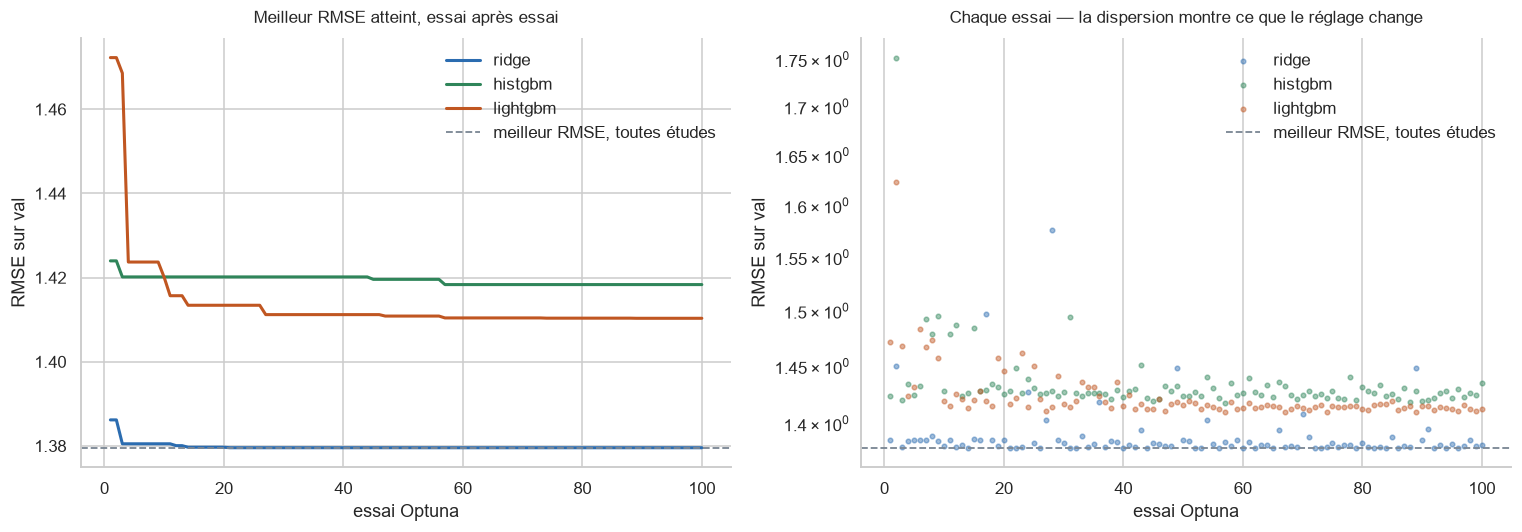

In [6]:
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(14, 5))

for nom in APPRENANTS:
    serie = (essais[essais['tags.modele'] == nom]
             .sort_values('essai')['metrics.val_rmse'])
    if serie.empty:
        continue
    # Meilleur RMSE atteint jusqu'a l'essai n : ce que l'optimisation a gagne
    gauche.plot(range(1, len(serie) + 1), serie.cummin(),
                color=COULEURS[nom], lw=2, label=nom)
    droite.scatter(range(1, len(serie) + 1), serie, s=9, alpha=0.45,
                   color=COULEURS[nom], label=nom)

# Le meilleur RMSE toutes etudes confondues, trace sur les deux panneaux : sans
# ce repere, une courbe qui descend donne l'illusion du progres alors qu'elle
# reste au-dessus de ce qu'une autre etude a deja atteint.
meilleur_global = comparaison.loc[APPRENANTS, 'rmse'].min()
for ax in (gauche, droite):
    ax.axhline(meilleur_global, color='#7b8794', ls='--', lw=1.2,
               label='meilleur RMSE, toutes études')

gauche.set_title('Meilleur RMSE atteint, essai après essai', fontsize=11, pad=10)
gauche.set_xlabel('essai Optuna')
gauche.set_ylabel('RMSE sur val')
gauche.legend(frameon=False)

droite.set_title('Chaque essai — la dispersion montre ce que le réglage change',
                 fontsize=11, pad=10)
droite.set_xlabel('essai Optuna')
droite.set_ylabel('RMSE sur val')
droite.set_yscale('log')
droite.legend(frameon=False)
for ax in (gauche, droite):
    for cote in ('top', 'right'):
        ax.spines[cote].set_visible(False)

fig.tight_layout()
FIGURES.mkdir(parents=True, exist_ok=True)
chemin = FIGURES / 'panel_optimisation_optuna.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

### 4.1 Quels hyperparamètres ont réellement compté ?

In [7]:
from optuna.distributions import IntDistribution
from optuna.trial import create_trial

optuna.logging.set_verbosity(optuna.logging.WARNING)

etudes = {}
for modele in APPRENANTS:
    # Les bornes viennent de training.ESPACES, pas d'une copie locale
    distributions = training.distributions_optuna(modele)
    if not distributions:
        continue

    reconstitues = []
    for _, essai in essais[essais['tags.modele'] == modele].iterrows():
        # MLflow stocke les parametres en texte : on retrouve le type d'origine
        parametres = {
            nom: (int(essai[f'params.{nom}']) if isinstance(loi, IntDistribution)
                  else float(essai[f'params.{nom}']))
            for nom, loi in distributions.items()}
        reconstitues.append(create_trial(params=parametres,
                                         distributions=distributions,
                                         value=float(essai['metrics.val_rmse'])))

    etude = optuna.create_study(direction='minimize', study_name=modele)
    etude.add_trials(reconstitues)
    etudes[modele] = etude

# Controle : le meilleur essai reconstitue doit egaler celui qu'a enregistre le
# run parent. Sinon la reconstitution aurait perdu, deforme ou melange un essai.
for modele, etude in etudes.items():
    enregistre = float(parents.loc[parents['tags.modele'] == modele,
                                   'metrics.val_rmse'].iloc[0])
    assert abs(etude.best_value - enregistre) < 1e-9, modele
    print(f'{modele:<10} {len(etude.trials):>3} essais reconstitués | '
          f'meilleur {etude.best_value:.8f} (conforme au run parent)')
    print(f'           {etude.best_params}')

ridge      100 essais reconstitués | meilleur 1.37955038 (conforme au run parent)
           {'alpha': 166.65762848418208}
histgbm    100 essais reconstitués | meilleur 1.41833081 (conforme au run parent)
           {'learning_rate': 0.011559863455476252, 'max_iter': 460, 'max_leaf_nodes': 242, 'min_samples_leaf': 45, 'l2_regularization': 3.236652810064182e-07}
lightgbm   100 essais reconstitués | meilleur 1.41032019 (conforme au run parent)
           {'learning_rate': 0.01046478152418952, 'n_estimators': 596, 'num_leaves': 30, 'min_child_samples': 35, 'subsample': 0.9814967771089853, 'colsample_bytree': 0.7602368724306572, 'reg_lambda': 0.08700245199068866}


écrit : panel_optuna_importances.png


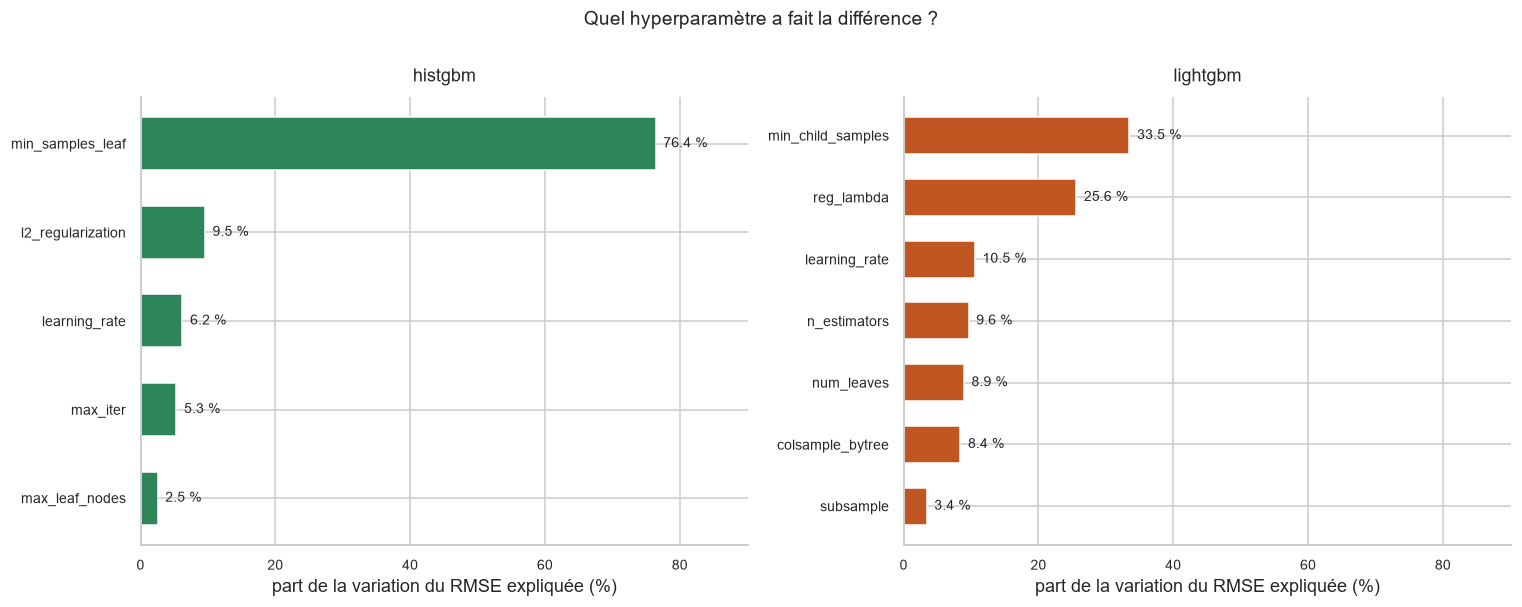

In [8]:
# Part de la variation du RMSE attribuable a chaque hyperparametre.
# Ridge n'en a qu'un, alpha : sa part vaut 100 % par construction, le tracer
# n'apprendrait rien.
importances = {m: optuna.importance.get_param_importances(etudes[m])
               for m in etudes if len(training.ESPACES[m]) > 1}

plafond = 100 * max(max(parts.values()) for parts in importances.values())

fig, axes = plt.subplots(1, len(importances), figsize=(7 * len(importances), 5.5),
                         sharex=True, squeeze=False)
for ax, (modele, parts) in zip(axes[0], importances.items()):
    noms = list(parts)[::-1]                      # du moins au plus important
    valeurs = [100 * parts[nom] for nom in noms]
    ax.barh(noms, valeurs, color=COULEURS[modele], height=0.6)
    for y, valeur in enumerate(valeurs):
        ax.text(valeur + plafond * 0.015, y, f'{valeur:.1f} %',
                va='center', fontsize=9)
    ax.set_xlim(0, plafond * 1.18)
    ax.set_xlabel('part de la variation du RMSE expliquée (%)')
    ax.set_title(modele, fontsize=11.5, pad=10)
    ax.tick_params(labelsize=9)
    for cote in ('top', 'right'):
        ax.spines[cote].set_visible(False)

fig.suptitle('Quel hyperparamètre a fait la différence ?', fontsize=12.5, y=1.0)
fig.tight_layout()
chemin = FIGURES / 'panel_optuna_importances.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

## 5. Prédictions et résidus

Les rendements du panel couvrent deux ordres de grandeur : les axes sont donc **logarithmiques**, sinon les 1,5 t/ha du soja s'écraseraient contre l'axe et seules les pommes de terre resteraient lisibles.


écrit : panel_predictions_vs_reel.png


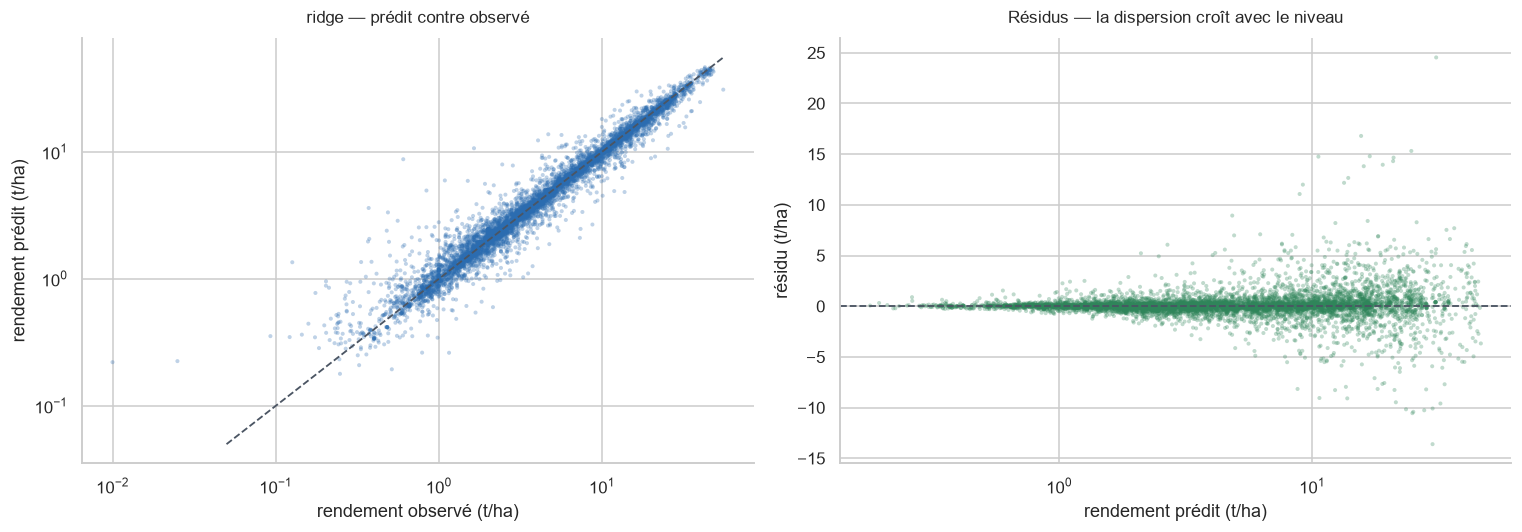


Écart-type du résidu par décile de prédiction (t/ha) :
0    0.241
1    0.350
2    0.472
3    0.586
4    0.656
5    0.892
6    1.184
7    1.637
8    2.039
9    2.945


In [9]:
retenu_provisoire = next(m for m in comparaison.index if m not in REFERENCES)
pred = predictions[retenu_provisoire]

fig, (gauche, droite) = plt.subplots(1, 2, figsize=(14, 5))

gauche.scatter(y_val, pred, s=7, alpha=0.3, color=BLUE, edgecolors='none')
bornes = [max(y_val.min(), 0.05), y_val.max()]
gauche.plot(bornes, bornes, color='#4b5563', lw=1.2, ls='--')
gauche.set_xscale('log')
gauche.set_yscale('log')
gauche.set_xlabel('rendement observé (t/ha)')
gauche.set_ylabel('rendement prédit (t/ha)')
gauche.set_title(f'{retenu_provisoire} — prédit contre observé', fontsize=11, pad=10)

residus = np.asarray(y_val) - pred
droite.scatter(pred, residus, s=7, alpha=0.3, color=GREEN, edgecolors='none')
droite.axhline(0, color='#4b5563', lw=1.2, ls='--')
droite.set_xscale('log')
droite.set_xlabel('rendement prédit (t/ha)')
droite.set_ylabel('résidu (t/ha)')
droite.set_title('Résidus — la dispersion croît avec le niveau', fontsize=11, pad=10)

for ax in (gauche, droite):
    for cote in ('top', 'right'):
        ax.spines[cote].set_visible(False)

fig.tight_layout()
chemin = FIGURES / 'panel_predictions_vs_reel.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

# L'heteroscedasticite se mesure, elle ne se devine pas : ecart-type du residu
# par decile de prediction. Consequence directe pour l'API, qui devrait
# calibrer son intervalle PAR NIVEAU et non une fois pour toutes.
deciles = pd.qcut(pred, 10, labels=False, duplicates='drop')
print('\nÉcart-type du résidu par décile de prédiction (t/ha) :')
print(pd.Series(residus).groupby(deciles).std().round(3).to_string())

## 6. L'erreur est-elle uniforme entre cultures et entre pays ?

Un RMSE global peut masquer une culture ou une région systématiquement mal traitée. Les niveaux variant d'un facteur 11 entre cultures, seule l'erreur **relative** est comparable.


Modèle : ridge

                         n  moyenne_observee   rmse    mae     r2  mae_relative_%
Item                                                                             
Plantains and others   350             9.493  2.241  0.729  0.899           7.683
Potatoes              1096            18.046  2.204  1.431  0.951           7.928
Cassava                724            10.288  1.571  0.854  0.927           8.302
Rice, paddy            824             3.578  0.513  0.308  0.930           8.597
Sweet potatoes         815            10.050  1.897  0.874  0.935           8.697
Yams                   420             8.479  1.543  0.745  0.887           8.781
Maize                 1160             4.044  0.788  0.419  0.960          10.349
Wheat                  861             2.967  0.512  0.336  0.929          11.325
Soybeans               629             1.591  0.364  0.236  0.770          14.829
Sorghum                734             2.043  0.778  0.343  0.855          16.767


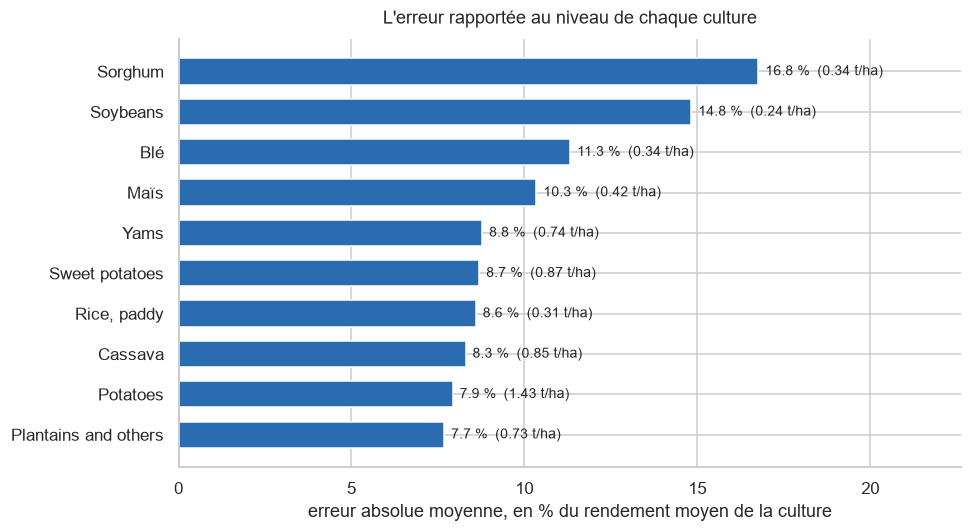

In [10]:
par_culture = metriques_par_culture(val, pred, colonne='Item', cible=CIBLE)
par_culture['mae_relative_%'] = 100 * par_culture['mae'] / par_culture['moyenne_observee']
par_culture = par_culture.sort_values('mae_relative_%')

print(f'Modèle : {retenu_provisoire}\n')
print(par_culture.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
noms = [CULTURES_EN_FRANCAIS.get(c, c) for c in par_culture.index]
ax.barh(noms, par_culture['mae_relative_%'], color=BLUE, height=0.65)
for y, (valeur, absolu) in enumerate(zip(par_culture['mae_relative_%'],
                                         par_culture['mae'])):
    ax.text(valeur + 0.2, y, f'{valeur:.1f} %  ({absolu:.2f} t/ha)',
            va='center', fontsize=9)
ax.set_xlim(0, par_culture['mae_relative_%'].max() * 1.35)
ax.set_xlabel('erreur absolue moyenne, en % du rendement moyen de la culture')
ax.set_title("L'erreur rapportée au niveau de chaque culture", fontsize=11.5, pad=10)
for cote in ('top', 'right'):
    ax.spines[cote].set_visible(False)
fig.tight_layout()
chemin = FIGURES / 'panel_erreur_par_culture.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('\nécrit :', chemin.name)
plt.show()

In [11]:
# Meme question par pays. On ne garde que ceux qui ont assez d'observations
# dans val pour qu'une moyenne veuille dire quelque chose.
par_pays = (pd.DataFrame({'Area': val['Area'].to_numpy(),
                          'erreur': np.abs(residus),
                          'niveau': y_val.to_numpy()})
            .groupby('Area')
            .agg(n=('erreur', 'size'), mae=('erreur', 'mean'),
                 niveau=('niveau', 'mean')))
par_pays = par_pays[par_pays['n'] >= 20]
par_pays['mae_relative_%'] = 100 * par_pays['mae'] / par_pays['niveau']
par_pays = par_pays.sort_values('mae_relative_%')

print(f'{len(par_pays)} pays avec au moins 20 observations dans val\n')
print('Les 5 mieux prédits :')
print(par_pays.head(5).round(2).to_string())
print('\nLes 5 moins bien prédits :')
print(par_pays.tail(5).round(2).to_string())
print(f"\nétendue de l'erreur relative : {par_pays['mae_relative_%'].min():.1f} % "
      f"à {par_pays['mae_relative_%'].max():.1f} %")

175 pays avec au moins 20 observations dans val

Les 5 mieux prédits :
                    n   mae  niveau  mae_relative_%
Area                                               
Comoros            42  0.08    5.17            1.57
Cabo Verde         28  0.19   11.37            1.65
Niue               21  0.14    7.72            1.85
Equatorial Guinea  21  0.10    3.98            2.42
Tonga              28  0.33   12.45            2.62

Les 5 moins bien prédits :
                      n   mae  niveau  mae_relative_%
Area                                                 
Trinidad and Tobago  42  0.78    3.52           22.11
Senegal              42  2.29    9.36           24.45
Belize               63  2.39    9.21           25.95
Botswana             20  0.36    0.72           50.76
Eritrea              28  0.84    1.56           53.98

étendue de l'erreur relative : 1.6 % à 54.0 %


## 7. Quelles variables pèsent réellement ?

L'importance est mesurée par **permutation sur les colonnes d'origine** : le Pipeline portant lui-même l'encodage, brasser `Area` mélange d'un coup ses 206 indicatrices. C'est la bonne unité de lecture — « que perd-on si l'on ignore le pays ? » — et elle est hors de portée d'une mesure faite après encodage.


In [12]:
# Degradation du RMSE quand une colonne est melangee : plus elle est grande,
# plus le modele dependait de cette colonne.
mesures_perm = {}
for nom in APPRENANTS:
    perm = permutation_importance(modeles[nom], X_val, y_val, n_repeats=5,
                                  random_state=42,
                                  scoring='neg_root_mean_squared_error')
    mesures_perm[nom] = pd.Series(perm.importances_mean, index=FEATURES)

importance = pd.DataFrame(mesures_perm)
importance['moyenne'] = importance.mean(axis=1)
importance = importance.sort_values('moyenne', ascending=False)

print('Dégradation du RMSE sur val quand la colonne est mélangée (t/ha)\n')
print(importance.round(4).to_string())

Dégradation du RMSE sur val quand la colonne est mélangée (t/ha)

               ridge  histgbm  lightgbm  moyenne
lag1          5.3026   6.9088    6.1313   6.1142
lag2          1.2008   0.6654    1.0706   0.9790
lag3          0.9591   0.6051    0.6198   0.7280
Item          0.0298   0.0338    0.0412   0.0350
pesticides_t  0.0003   0.0257    0.0298   0.0186
rain_mm       0.0001   0.0054    0.0139   0.0064
avg_temp      0.0018   0.0108    0.0035   0.0054
Area          0.0034   0.0014    0.0015   0.0021


### 7.1 SHAP : décomposer une prédiction, plutôt que mesurer une dégradation

La permutation répond à « que perd-on en ignorant cette variable ? », SHAP à « dans cette prédiction-ci, quelle part vient de quelle variable ? ». Si les deux concordent, la conclusion ne tient pas à la méthode.

**Le regroupement des colonnes encodées est une condition de validité.** Après encodage la matrice compte **222 colonnes** : 6 quantitatives, 206 indicatrices de pays, 10 de culture — une valeur lue sur `Area_France` ne parle que d'un pays parmi 206. Les valeurs SHAP étant **additives**, les sommer par variable d'origine est exact ; la cellule le vérifie.


In [13]:
def variable_source(colonne):
    """Remonte d'une colonne encodee a la variable dont elle est issue.

    `Area_France`, `Area_Belize`... viennent toutes de `Area`. Les colonnes
    quantitatives portent deja le nom de leur variable.
    """
    for origine in jeu.categorielles:
        if colonne.startswith(origine + '_'):
            return origine
    return colonne


def grouper(explication, X, colonnes):
    """Somme les valeurs SHAP des colonnes issues d'une meme variable.

    Renvoie DEUX objets de valeurs identiques mais de `data` different :
      - `couleur` : la valeur numerique, NaN pour les categorielles. Le
        beeswarm colore par cette valeur — une categorie n'ayant ni haut ni
        bas, NaN la laisse en gris plutot que d'inventer un ordre ;
      - `lecture` : la modalite en clair, pour etiqueter les waterfalls.
    """
    positions = {}
    for rang, colonne in enumerate(colonnes):
        positions.setdefault(variable_source(colonne), []).append(rang)
    noms = list(positions)

    valeurs = np.column_stack([explication.values[:, rangs].sum(axis=1)
                               for rangs in positions.values()])
    couleur = np.column_stack([
        np.full(len(X), np.nan) if nom in jeu.categorielles
        else X[nom].astype(float).to_numpy() for nom in noms])
    lisible = np.column_stack([
        X[nom].astype(str).to_numpy() if nom in jeu.categorielles
        else X[nom].astype(float).round(2).astype(str).to_numpy()
        for nom in noms])

    commun = dict(values=valeurs, base_values=explication.base_values,
                  feature_names=noms)
    return (shap.Explanation(data=couleur, **commun),
            shap.Explanation(data=lisible, **commun))


# Un echantillon suffit : les moyennes de contributions sont stables bien avant
# les 7 613 lignes de validation.
ECHANTILLON_SHAP = 3_000
X_shap = X_val.sample(ECHANTILLON_SHAP, random_state=42)

explications, contributions = {}, {}
for nom in ('ridge', 'lightgbm'):
    pretraitement, estimateur = modeles[nom][:-1], modeles[nom][-1]
    Xt = pd.DataFrame(pretraitement.transform(X_shap),
                      columns=pretraitement.get_feature_names_out(),
                      index=X_shap.index)
    debut = time.perf_counter()
    if nom == 'ridge':
        # Fond COMPLET. Le defaut de shap (100 lignes) place la reference a
        # 8,52 t/ha quand la moyenne reelle des predictions est 7,03 : toutes
        # les contributions s en trouvent decalees. Sur un modele lineaire le
        # fond complet ne coute rien, l explainer n a besoin que de E[x].
        masque = shap.maskers.Independent(Xt, max_samples=len(Xt))
        par_colonne = shap.Explainer(estimateur, masque)(Xt)
    else:
        # `tree_path_dependent` : moins d une seconde, contre un quart d heure
        # pour un fond complet interventionnel. Sa reference est la
        # distribution d apprentissage et non l echantillon, donc seul le
        # CLASSEMENT se compare a ridge — pas les valeurs absolues.
        par_colonne = shap.TreeExplainer(estimateur)(Xt)
    duree = time.perf_counter() - debut

    # REGROUPEMENT IMMEDIAT, avant toute lecture.
    explications[nom] = grouper(par_colonne, X_shap, Xt.columns)
    contributions[nom] = pd.Series(
        np.abs(explications[nom][0].values).mean(axis=0),
        index=explications[nom][0].feature_names)
    print(f'{nom:<10} {Xt.shape[1]} colonnes -> '
          f'{len(contributions[nom])} variables   ({duree:.1f} s)')

shap_variables = pd.DataFrame(contributions).sort_values('ridge', ascending=False)

# Controle d additivite : si le regroupement etait faux, la somme des
# contributions plus la base ne redonnerait pas la prediction.
couleur_ridge, lecture_ridge = explications['ridge']
reconstruit = couleur_ridge.values.sum(axis=1) + couleur_ridge.base_values
ecart = np.abs(reconstruit - modeles['ridge'].predict(X_shap)).max()
print(f'\nadditivité : écart max |somme SHAP + base - prédiction| = {ecart:.1e} t/ha')
print(f'référence E[f(X)] = {float(np.unique(couleur_ridge.base_values)[0]):.4f} '
      f't/ha, pour une prédiction moyenne de '
      f'{modeles["ridge"].predict(X_shap).mean():.4f} t/ha')

print('\nContribution SHAP moyenne |valeur|, en t/ha, par variable d origine :\n')
shap_variables.round(4)

ridge      222 colonnes -> 8 variables   (0.1 s)
lightgbm   222 colonnes -> 8 variables   (0.9 s)

additivité : écart max |somme SHAP + base - prédiction| = 7.1e-15 t/ha
référence E[f(X)] = 7.0265 t/ha, pour une prédiction moyenne de 7.0265 t/ha

Contribution SHAP moyenne |valeur|, en t/ha, par variable d origine :



,ridge,lightgbm
lag1,3.3034,3.7560
lag2,1.0893,0.9768
lag3,0.9281,0.4202
Item,0.1524,0.0685
Area,0.0584,0.0184
avg_temp,0.0410,0.0265
rain_mm,0.0114,0.0232
pesticides_t,0.0079,0.0285


### 7.2 Lecture globale

La barre donne la contribution moyenne de chaque variable, le beeswarm sa **distribution** — un point par observation, coloré par la valeur de la variable. Les quantitatives vont du bleu (valeur basse) au rouge (haute) ; `Area` et `Item` ressortent **en gris** : une catégorie n'a ni haut ni bas, et un dégradé inventerait un ordre entre la France et le Belize.


écrit : panel_shap_bar.png


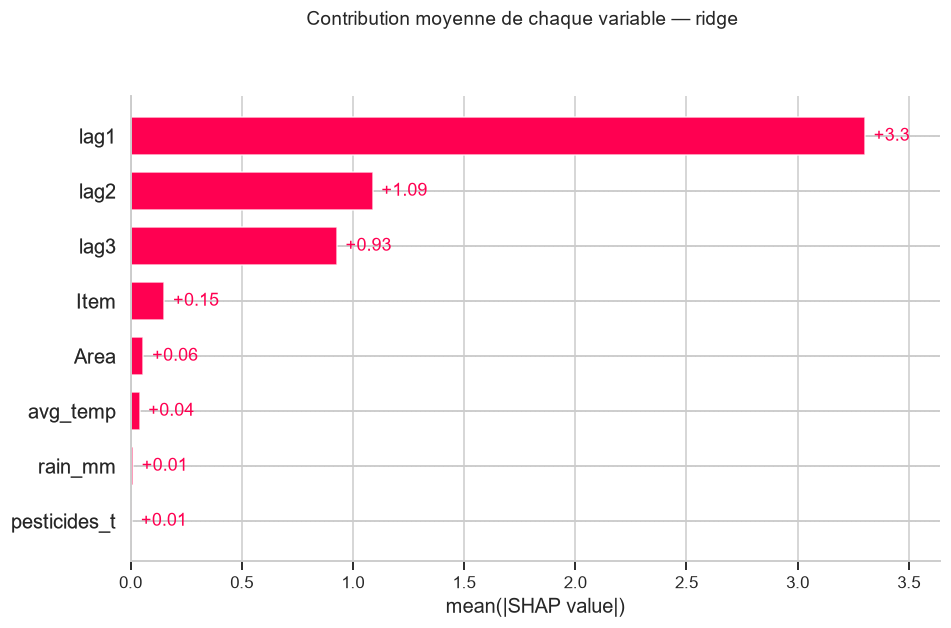

In [14]:
plt.figure()
shap.plots.bar(couleur_ridge, max_display=len(FEATURES), show=False)
figure = plt.gcf()
figure.set_size_inches(9.5, 5.5)
figure.suptitle('Contribution moyenne de chaque variable — ridge',
                fontsize=12.5, y=1.02)
chemin = FIGURES / 'panel_shap_bar.png'
figure.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

écrit : panel_shap_beeswarm.png


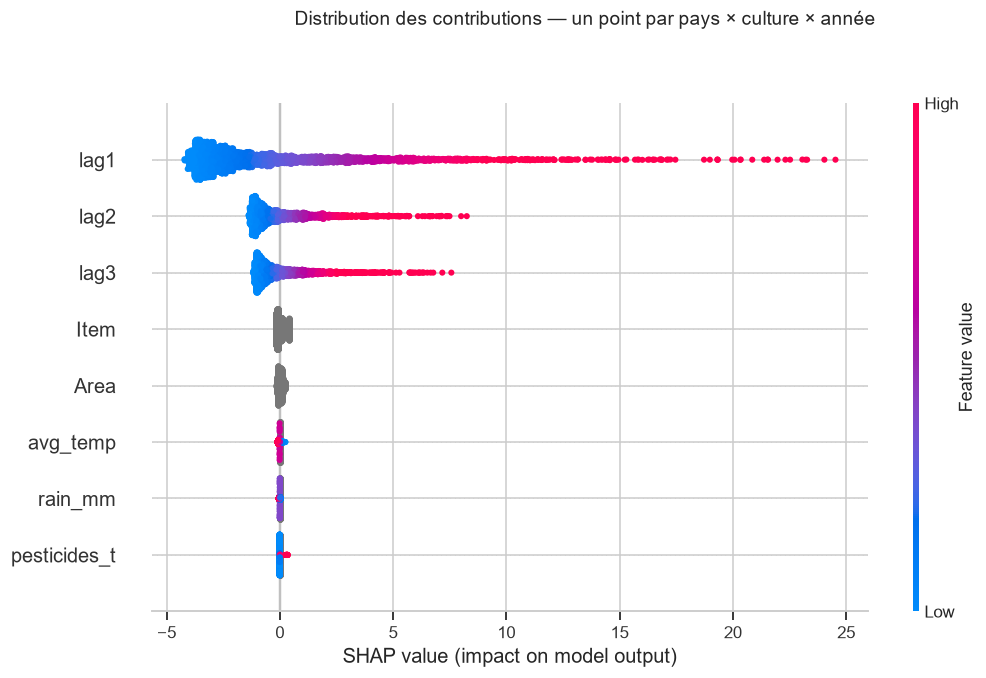

In [15]:
# Le beeswarm calcule des quantiles par variable pour la couleur : sur `Area` et
# `Item`, remplies de NaN a dessein, numpy previent qu une tranche est vide.
# C est attendu, et c est precisement ce qui les laisse en gris.
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    plt.figure()
    shap.plots.beeswarm(couleur_ridge, max_display=len(FEATURES), show=False)

figure = plt.gcf()
figure.set_size_inches(10.5, 6)
figure.suptitle('Distribution des contributions — un point par pays × culture × année',
                fontsize=12.5, y=1.02)
chemin = FIGURES / 'panel_shap_beeswarm.png'
figure.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

In [16]:
# Les trois blocs, en part de la decomposition totale. C est le chiffre a
# retenir pour le contrat d entree de l application.
retards = [c for c in PANEL_FEATURES_PREVISION if c in shap_variables.index]
conditions = [c for c in PANEL_COVARIATES if c in shap_variables.index]
total = shap_variables['ridge'].sum()

for libelle, bloc in (('les trois retards', retards),
                      ('l identité pays × culture', jeu.categorielles),
                      ('les conditions (température, pluie, pesticides)', conditions)):
    part = 100 * shap_variables.loc[bloc, 'ridge'].sum() / total
    print(f'  {libelle:<48} {part:5.1f} %')

# Les deux familles de modeles sont-elles d accord sur l ordre ?
confrontation = pd.DataFrame({
    'SHAP ridge': shap_variables['ridge'],
    'SHAP lightgbm': shap_variables['lightgbm'],
    'permutation (moyenne)': importance['moyenne'],
})
for colonne in confrontation.columns:
    confrontation[f'rang {colonne.split()[-1]}'] = (
        confrontation[colonne].rank(ascending=False).astype(int))
print('\nTrois mesures de natures différentes, confrontées :\n')
confrontation.round(4)

  les trois retards                                 95.2 %
  l identité pays × culture                          3.8 %
  les conditions (température, pluie, pesticides)    1.1 %

Trois mesures de natures différentes, confrontées :



,SHAP ridge,SHAP lightgbm,permutation (moyenne),rang ridge,rang lightgbm,rang (moyenne)
Area,0.0584,0.0184,0.0021,5,8,8
Item,0.1524,0.0685,0.0350,4,4,4
avg_temp,0.0410,0.0265,0.0054,6,6,7
lag1,3.3034,3.7560,6.1142,1,1,1
lag2,1.0893,0.9768,0.9790,2,2,2
lag3,0.9281,0.4202,0.7280,3,3,3
pesticides_t,0.0079,0.0285,0.0186,8,5,5
rain_mm,0.0114,0.0232,0.0064,7,7,6


### 7.3 Trois cas locaux

Une moyenne cache les cas. Chaque cascade part de la référence `E[f(X)]` — ce que le modèle prédirait sans rien savoir — et chaque variable pousse vers le haut ou vers le bas jusqu'à la prédiction finale. Les trois cas couvrent ce que le modèle sait faire et ce qu'il ne sait pas : la plus forte hausse réelle d'une année sur l'autre, un cas médian, sa plus grande erreur.


écrit : panel_shap_waterfall_1.png   (Belize / Plantains and others, lag1 16.34)


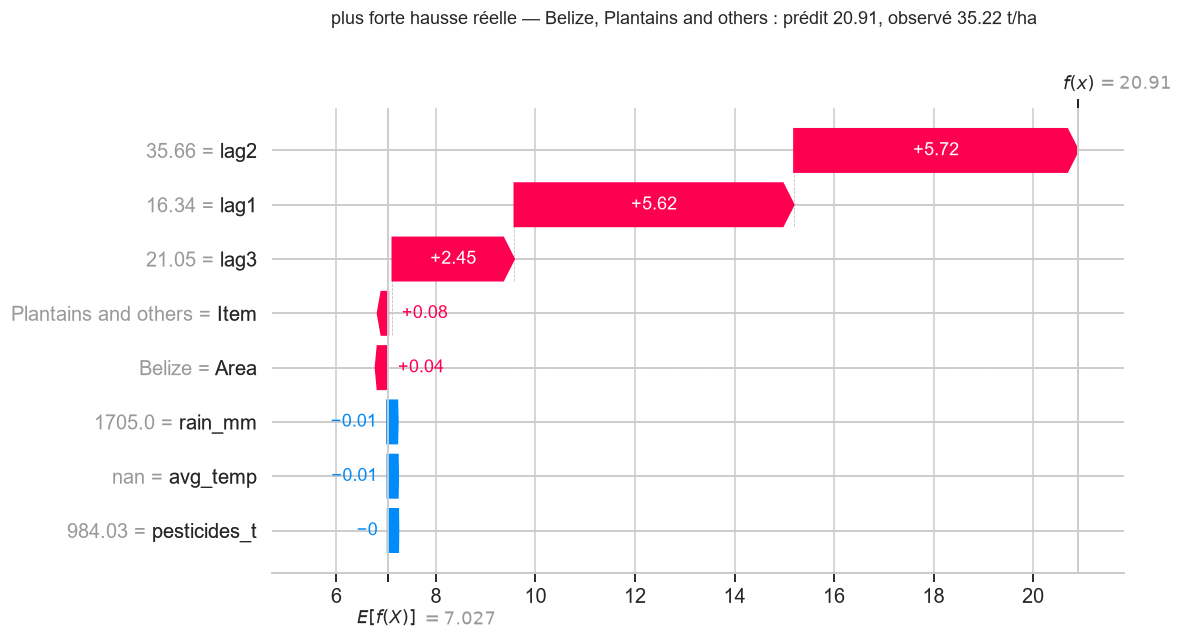

écrit : panel_shap_waterfall_2.png   (The former Yugoslav Republic of Macedonia / Maize, lag1 3.84)


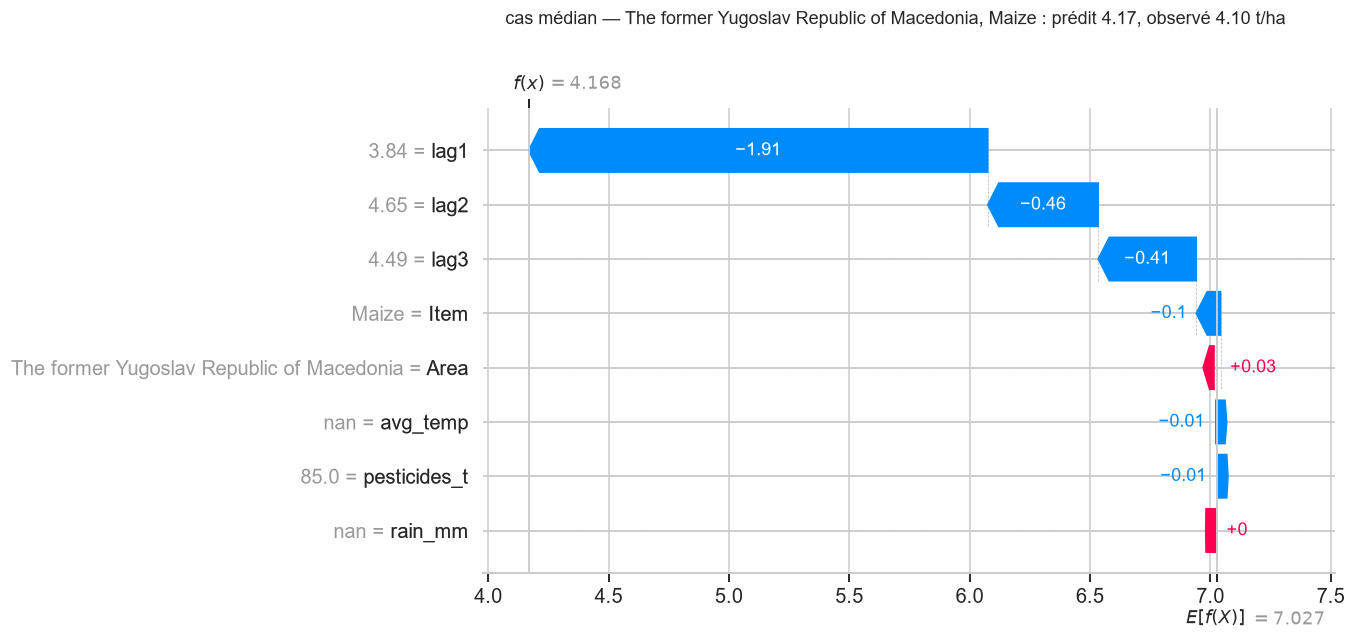

écrit : panel_shap_waterfall_3.png   (Barbados / Cassava, lag1 17.17)


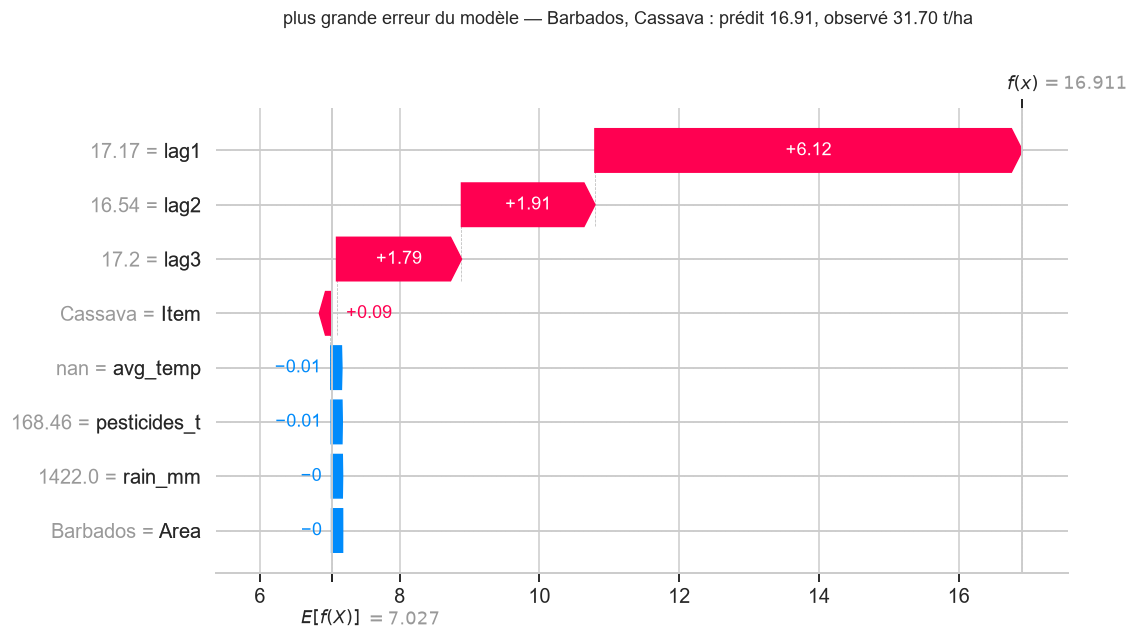

In [17]:
prediction_shap = modeles['ridge'].predict(X_shap)
observe_shap = val.loc[X_shap.index, CIBLE].to_numpy()
saut_reel = observe_shap - X_shap['lag1'].to_numpy()

CAS = {
    'plus forte hausse réelle': int(np.argmax(saut_reel)),
    'cas médian': int(np.argsort(prediction_shap)[len(prediction_shap) // 2]),
    'plus grande erreur du modèle':
        int(np.argmax(np.abs(observe_shap - prediction_shap))),
}

# Une figure par cas : shap.plots.waterfall place ses etiquettes hors des axes
# et ne supporte pas d etre place dans une grille de sous-graphiques.
for rang, (titre, i) in enumerate(CAS.items(), start=1):
    ligne = X_shap.iloc[i]
    plt.figure()
    shap.plots.waterfall(lecture_ridge[i], max_display=9, show=False)
    figure = plt.gcf()
    figure.set_size_inches(10, 5.5)
    figure.suptitle(f'{titre} — {ligne["Area"]}, {ligne["Item"]} : prédit '
                    f'{prediction_shap[i]:.2f}, observé {observe_shap[i]:.2f} t/ha',
                    fontsize=12, y=1.04)
    chemin = FIGURES / f'panel_shap_waterfall_{rang}.png'
    figure.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
    print(f'écrit : {chemin.name}   ({ligne["Area"]} / {ligne["Item"]}, '
          f'lag1 {ligne["lag1"]:.2f})')
    plt.show()

### Verdict : trois méthodes, un seul classement

Coefficients, permutation et SHAP ne mesurent pas la même chose. **Ils donnent pourtant le même ordre.**

Les trois retards portent l'essentiel ; l'identité du pays et de la culture, quelques pour cent ; **les trois conditions — température, pluviométrie, pesticides — environ un pour cent**. Là où `lag1` s'étale sur plus de vingt tonnes, elles forment une barre verticale collée à zéro. Sur sa plus grande erreur, le modèle reconduit le passé et manque un quasi-doublement, sans qu'aucune condition ne l'ait alerté.

**Conséquence pour l'application.** Demander sa température et son usage de pesticides à l'utilisateur produirait une interface qui *semble* répondre aux conditions sans le faire : la prédiction bougerait d'un centième de tonne. Ce modèle prévoit la suite d'une série nationale, il ne simule pas l'effet d'une pratique agricole.


## 8. Ablation : ce que coûte le retrait de chaque bloc

La permutation dit de quoi le modèle *se sert*. L'ablation dit ce qu'on *perdrait* à ne pas collecter une information — c'est elle qui décide du contrat d'entrée de l'application.

| Variante | La question qu'elle tranche |
|---|---|
| sans identité | `Area` et `Item` servent-ils, les retards étant là ? |
| sans covariables | température et pesticides apportent-ils quelque chose ? |
| **sans retards** | ce que coûterait de répondre à un agriculteur sans aucun passé |
| avec `choc` | la borne de nowcasting : connaître l'année courante des autres cultures |

Toutes partagent le `alpha` du modèle déjà optimisé : l'ablation mesure le retrait d'un bloc, pas un nouveau réglage.


In [18]:
# Le meme alpha partout : il vient du modele deja optimise, pas d'une nouvelle
# recherche. Lu sur l'objet, donc sans dependance a MLflow.
ALPHA = modeles['ridge'].named_steps['modele'].alpha

BLOCS = {
    'tout (les 8 variables)': list(FEATURES),
    'sans identité (Area, Item)': [c for c in FEATURES
                                   if c not in PANEL_FEATURES_IDENTITE],
    'sans covariables': [c for c in FEATURES if c not in PANEL_COVARIATES],
    'retards seuls': list(PANEL_FEATURES_PREVISION),
    'sans retards (conditions seules)': [*PANEL_FEATURES_IDENTITE,
                                         *PANEL_COVARIATES],
    'tout + choc (nowcast)': [*FEATURES, 'choc'],
}

lignes = []
for libelle, colonnes in BLOCS.items():
    p = training.construire_pipeline('ridge', {'alpha': ALPHA}, colonnes, SOURCE)
    p.fit(train[colonnes], train[CIBLE])
    lignes.append({'variables': libelle, 'n': len(colonnes),
                   **metriques_prediction(y_val, p.predict(val[colonnes]))})

ablation = pd.DataFrame(lignes).set_index('variables')
ablation['delta_rmse'] = ablation['rmse'] - ablation.loc['tout (les 8 variables)', 'rmse']
ablation['delta_mae'] = ablation['mae'] - ablation.loc['tout (les 8 variables)', 'mae']

print(f'Ridge, alpha = {ALPHA:.4g}, ajusté sur train pour chaque variante\n')
ablation.round(4)

Ridge, alpha = 166.7, ajusté sur train pour chaque variante



,n,rmse,mae,r2,delta_rmse,delta_mae
variables,,,,,,
tout (les 8 variables),8,1.3796,0.6430,0.9680,0.0000,0.0000
"sans identité (Area, Item)",6,1.3780,0.6354,0.9681,-0.0016,-0.0076
sans covariables,5,1.3791,0.6411,0.9680,-0.0004,-0.0018
retards seuls,3,1.3775,0.6361,0.9681,-0.0021,-0.0069
sans retards (conditions seules),5,5.2129,3.1432,0.5434,3.8333,2.5003
tout + choc (nowcast),9,1.3743,0.6386,0.9683,-0.0052,-0.0043


### Verdict : les trois retards suffisent, et « tout le dataset » coûte un millième

**Retirer l'identité améliore le modèle** (1,3780 contre 1,3796), retirer les covariables aussi (1,3791), et les **trois retards seuls font mieux que les huit variables** (1,3775). Écarts minuscules, mais tous dans le même sens : `Area`, `Item`, `avg_temp`, `rain_mm` et `pesticides_t` n'apportent rien. Le `alpha` retenu, **166,7**, le dit autrement — le modèle écrase lui-même les 222 colonnes du one-hot.

**Sans les retards, tout s'écroule** : 5,2129 de RMSE, 3,8 fois l'erreur du modèle complet, R² de 0,968 à 0,543. **`choc` gagnerait 0,4 %** (1,3743) — rien à regretter d'avoir écarté une variable qu'aucune prévision ne peut connaître.

**Conséquence.** Le contrat d'entrée se réduit au pays, à la culture et aux trois retards que la table FAO fournit.


## 9. La recommandation de culture est-elle possible ?

Seconde fonction demandée, et la plus exigeante. Sur les parcelles simulées la réponse était négative : 0,0065 t/ha d'écart entre meilleure et pire culture, pour un classement identique sur 100 % des parcelles, indépendant de toute condition.

**Le contrefactuel n'est pas le même ici.** Les trois retards étant propres au couple (pays, culture), on ne peut pas recopier une ligne en changeant seulement la culture : chaque candidate reçoit **son** historique national — ce dont une application disposerait. **Et les cultures jamais cultivées dans le pays sont écartées** : sans ce garde-fou, interrogé sur la France, le modèle place le plantain en deuxième position.


In [19]:
sensibilite = sensibilite_culture_panel(modeles[retenu_provisoire], val, FEATURES)

print('Rendement prédit moyen par culture, historique national de chacune :')
rendements = sensibilite['rendement_moyen_par_culture']
print(pd.DataFrame({'t/ha': rendements.round(2),
                    'culture': [CULTURES_EN_FRANCAIS.get(c, c)
                                for c in rendements.index]}).to_string())

print(f"\n  écart moyen meilleure/pire   : {sensibilite['ecart_moyen_t_ha']:.2f} t/ha")
print(f"  écart médian                 : {sensibilite['ecart_median_t_ha']:.2f} t/ha")
print(f"  cultures candidates (moyenne): "
      f"{sensibilite['cultures_candidates_moyenne']:.1f} sur {val.Item.nunique()}")
print(f"  lignes écartées (monoculture): {sensibilite['lignes_ecartees']}")
print(f"\n  classement constant partout  : {sensibilite['classement_constant']}")
print(f"  pays au classement figé      : "
      f"{sensibilite['part_pays_classement_fige']:.1f} %")
print('\nPart des situations où chaque culture arrive en tête (%) :')
print(sensibilite['part_en_tete'].round(1).to_string())

Rendement prédit moyen par culture, historique national de chacune :
                       t/ha               culture
Potatoes              16.64              Potatoes
Cassava               10.09               Cassava
Sweet potatoes         9.62        Sweet potatoes
Plantains and others   9.44  Plantains and others
Yams                   8.73                  Yams
Rice, paddy            3.53           Rice, paddy
Maize                  3.52                  Maïs
Wheat                  2.67                   Blé
Sorghum                1.95               Sorghum
Soybeans               1.57              Soybeans

  écart moyen meilleure/pire   : 15.35 t/ha
  écart médian                 : 14.07 t/ha
  cultures candidates (moyenne): 6.4 sur 10
  lignes écartées (monoculture): 46

  classement constant partout  : False
  pays au classement figé      : 83.8 %

Part des situations où chaque culture arrive en tête (%) :
Potatoes                55.9
Cassava                 17.6
Sweet potatoes

### 9.1 Le classement en tonnage ne décide de rien

L'écart entre cultures est considérable, mais **presque entièrement dû au niveau de la culture** : une pomme de terre rend dix fois plus qu'un soja, et aucun agriculteur n'a besoin d'un modèle pour l'apprendre.

Le mail parle de la culture « la plus rentable » : c'est donc un classement **économique** qu'il faut, et il faut des prix. `config.PRIX_REFERENCE_FAOSTAT` n'en porte que pour quatre des dix cultures du panel — assez pour montrer que l'ordre change.


In [20]:
# CROP_MAPPING fait le pont entre les deux vocabulaires : il a ete construit a
# l'etape 1 pour rapprocher les parcelles simulees du referentiel FAO.
prix_panel = {panel: PRIX_REFERENCE_FAOSTAT[simule]['prix_eur_t']
              for simule, panel in CROP_MAPPING.items()}

economie = pd.DataFrame({
    'rendement prédit (t/ha)': rendements,
    'prix (EUR/t)': pd.Series(prix_panel),
}).dropna()
economie['produit brut (EUR/ha)'] = (economie['rendement prédit (t/ha)']
                                     * economie['prix (EUR/t)'])
economie['rang tonnage'] = economie['rendement prédit (t/ha)'].rank(ascending=False)
economie['rang valeur'] = economie['produit brut (EUR/ha)'].rank(ascending=False)

print(f'{len(economie)} cultures du panel sur {len(rendements)} ont un prix '
      f'de référence\n')
print(economie.sort_values('produit brut (EUR/ha)', ascending=False)
      .round(1).to_string())

inverse = int((economie['rang tonnage'] != economie['rang valeur']).sum())
print(f'\n{inverse} cultures sur {len(economie)} changent de rang entre le '
      f'classement en tonnes et le classement en valeur.')
print('\nCe qui manque pour aller au bout : les prix des six autres cultures')
print('(manioc, plantain, pomme de terre, sorgho, patate douce, igname), et les')
print('charges opérationnelles, que /recommend demande déjà à l utilisateur.')

4 cultures du panel sur 10 ont un prix de référence

             rendement prédit (t/ha)  prix (EUR/t)  produit brut (EUR/ha)  rang tonnage  rang valeur
Rice, paddy                      3.5         423.0                 1491.6           1.0          1.0
Maize                            3.5         267.0                  939.3           2.0          2.0
Soybeans                         1.6         450.0                  704.7           4.0          3.0
Wheat                            2.7         225.0                  600.0           3.0          4.0

2 cultures sur 4 changent de rang entre le classement en tonnes et le classement en valeur.

Ce qui manque pour aller au bout : les prix des six autres cultures
(manioc, plantain, pomme de terre, sorgho, patate douce, igname), et les
charges opérationnelles, que /recommend demande déjà à l utilisateur.


### Verdict : un classement par pays, pas un conseil personnalisé

**L'écart entre cultures est de 15,35 t/ha**, contre 0,0065 sur les parcelles simulées — un facteur 2 300. Le classement existe.

**Mais 83,8 % des pays ont une culture de tête qui ne change jamais**, et la section 7 chiffre `Item` à 0,035 t/ha contre 6,11 pour `lag1` : le classement est porté par l'historique national de chaque culture, pas par les conditions de la parcelle. En tonnage le conseil est d'ailleurs trivial — la pomme de terre arrive en tête dans 55,9 % des situations.

À présenter comme un classement national, jamais comme un conseil personnalisé. Il faut l'axe économique pour qu'il devienne une décision, et il manque six prix sur dix.


## 10. Contraintes de déploiement

L'erreur ne décide pas seule. Un modèle servi derrière une API doit répondre vite, tenir dans une image, et pouvoir être expliqué à un agriculteur.

In [21]:
deploiement = []
for nom in MODELES:
    chemin = training.chemin_modele(nom, jeu.artefact)
    latence = latence_prediction(modeles[nom], val, FEATURES)
    deploiement.append({
        'modele': nom,
        'role': 'reference' if nom in REFERENCES else 'modele',
        'RMSE': round(comparaison.loc[nom, 'rmse'], 4),
        'latence unitaire (ms)': round(latence['latence_unitaire_ms'], 2),
        'latence 1000 lignes (ms)': round(latence['latence_lot_ms'], 1),
        'taille (Ko)': round(chemin.stat().st_size / 1024, 1),
    })

pd.DataFrame(deploiement).set_index('modele')

,role,RMSE,latence unitaire (ms),latence 1000 lignes (ms),taille (Ko)
modele,,,,,
dummy,reference,7.8396,3.68,5.2,6.4
ridge,modele,1.3796,2.78,5.8,8.3
histgbm,modele,1.4183,13.11,19.4,10443.0
lightgbm,modele,1.4103,5.72,10.3,1659.8


## 11. Décision

> **Tout ce qui précède repose sur `val`. Le choix du modèle est arrêté ici, et ne sera pas révisé après l'ouverture de `test`.**

In [22]:
# Le tableau rassemble les criteres mesures plus haut. Aucun n'est pondere :
# c'est la lecture qui tranche, et elle s'ecrit en clair dans la cellule
# suivante.
mesures_deploiement = {d['modele']: d for d in deploiement}
candidats = [m for m in comparaison.index if m not in REFERENCES]

criteres = pd.DataFrame([
    {'critere': 'RMSE sur validation',
     'gagnant': candidats[0],
     'detail': ' | '.join(f'{m} {comparaison.loc[m, "rmse"]:.4f}'
                          for m in candidats)},
    {'critere': 'MAE sur validation',
     'gagnant': min(candidats, key=lambda m: comparaison.loc[m, 'mae']),
     'detail': ' | '.join(f'{m} {comparaison.loc[m, "mae"]:.4f} t/ha'
                          for m in candidats)},
    {'critere': 'ecart statistiquement reel ?',
     'gagnant': candidats[0],
     'detail': f'z = {test_apparie(candidats[0], candidats[1]):.1f} '
               f'contre {candidats[1]}'},
    {'critere': 'erreur relative entre cultures',
     'gagnant': 'voir section 6',
     'detail': f'etendue {par_culture["mae_relative_%"].min():.1f} - '
               f'{par_culture["mae_relative_%"].max():.1f} % sur '
               f'{retenu_provisoire}'},
    {'critere': 'latence unitaire',
     'gagnant': min(candidats,
                    key=lambda m: mesures_deploiement[m]['latence unitaire (ms)']),
     'detail': ' | '.join(f'{m} {mesures_deploiement[m]["latence unitaire (ms)"]} ms'
                          for m in candidats)},
    {'critere': 'taille de l artefact',
     'gagnant': min(candidats, key=lambda m: mesures_deploiement[m]['taille (Ko)']),
     'detail': ' | '.join(f'{m} {mesures_deploiement[m]["taille (Ko)"]:.0f} Ko'
                          for m in candidats)},
    {'critere': 'interpretabilite',
     'gagnant': 'ridge',
     'detail': 'coefficients lisibles ; les GBM exigent SHAP'},
]).set_index('critere')
criteres

,gagnant,detail
critere,,
RMSE sur validation,ridge,ridge 1.3796 | lightgbm 1.4103 | histgbm 1.4183
MAE sur validation,ridge,ridge 0.6430 t/ha | lightgbm 0.6506 t/ha | his...
ecart statistiquement reel ?,ridge,z = 2.7 contre lightgbm
erreur relative entre cultures,voir section 6,etendue 7.7 - 16.8 % sur ridge
latence unitaire,ridge,ridge 2.78 ms | lightgbm 5.72 ms | histgbm 13....
taille de l artefact,ridge,ridge 8 Ko | lightgbm 1660 Ko | histgbm 10443 Ko
interpretabilite,ridge,coefficients lisibles ; les GBM exigent SHAP


In [23]:
# LA decision. Elle se change a la main, en connaissance du tableau ci-dessus,
# et c'est elle qui gouverne tout ce qui suit : test, export, promotion.
MODELE_RETENU = candidats[0]

modele_final = modeles[MODELE_RETENU]
print(f'Modèle retenu : {MODELE_RETENU}')
print(f"  RMSE val {comparaison.loc[MODELE_RETENU, 'rmse']:.4f}  |  "
      f"MAE {comparaison.loc[MODELE_RETENU, 'mae']:.4f}  |  "
      f"R² {comparaison.loc[MODELE_RETENU, 'r2']:.4f}")
# L'avance se mesure sur le rival le plus proche, seule comparaison qui engage
rival = next(m for m in candidats if m != MODELE_RETENU)
ecart = comparaison.loc[rival, 'rmse'] - comparaison.loc[MODELE_RETENU, 'rmse']
print(f'  avance sur {rival} : {ecart:+.4f} de RMSE, soit '
      f"{100 * ecart / comparaison.loc[rival, 'rmse']:+.1f} %")

Modèle retenu : ridge
  RMSE val 1.3796  |  MAE 0.6430  |  R² 0.9680
  avance sur lightgbm : +0.0308 de RMSE, soit +2.2 %


### Le modèle retenu

**Ridge**, qui remporte les sept critères mesurés : meilleur RMSE, meilleure MAE, écart statistiquement établi (z = 2,7 contre LightGBM), latence la plus faible (environ 2 ms contre 5 et 11), artefact le plus léger — **8,3 Ko contre 10,2 Mo, un facteur 1 260** — et le seul dont les coefficients se lisent sans outil d'interprétation. Son avance est ici **réelle** : 2,2 % de RMSE sur LightGBM.

Et structurelle. Le découpage est chronologique, les rendements progressent, et **3 057 lignes de test dépassent le maximum historique de leur propre série** — 40,8 % de celles dont la série a un historique connu, 39,7 % du jeu entier. Or la prédiction d'un arbre est une **moyenne** de feuille : son étendue reste intérieure à celle de la cible. Une régression sur les retards, coefficients sommant à 0,97, n'a pas cette borne. La section 12.1 le mesure ; aucun booster n'y changerait rien, et c'est pour l'établir qu'ils sont ici.


## 12. Ouverture du jeu de test

Première et unique lecture de `test` — les années 2010 à 2016, que ni l'optimisation ni la comparaison n'ont vues. C'est l'écart entre `val` et `test` qui compte, plus que la valeur de `test` seule.

La section 12.1 y confronte ensuite les quatre modèles. Cette seconde lecture **décrit**, elle ne choisit pas : se servir de `test` pour *arrêter* un choix l'invalide, s'en servir pour *montrer* ce qui sépare les candidats une fois le choix fait ne l'invalide pas.


In [24]:
# Premiere et unique lecture de test dans ce notebook
_, _, test = training.charger_partitions(avec_test=True, source=SOURCE)
X_test, y_test = test[FEATURES], test[CIBLE]
prediction_test = modele_final.predict(X_test)

final = pd.DataFrame([
    {'jeu': 'val', 'annees': f"{annees['val'][0]}-{annees['val'][1]}",
     'n': len(val), **metriques_prediction(y_val, predictions[MODELE_RETENU])},
    {'jeu': 'test', 'annees': f"{annees['test'][0]}-{annees['test'][1]}",
     'n': len(test), **metriques_prediction(y_test, prediction_test)},
]).set_index('jeu')

print(f'Modèle retenu : {MODELE_RETENU}\n')
print(final.round(4).to_string())
print(f"\nécart val -> test : "
      f"{final.loc['test', 'rmse'] - final.loc['val', 'rmse']:+.4f} de RMSE, "
      f"{final.loc['test', 'mae'] - final.loc['val', 'mae']:+.4f} de MAE")

# Rapportee au niveau general, l'erreur dit si le modele perd en justesse ou si
# c'est seulement l'echelle des rendements qui a monte.
for jeu_nom, observe in (('val', y_val), ('test', y_test)):
    print(f"  {jeu_nom:<5} MAE {final.loc[jeu_nom, 'mae']:.4f} t/ha = "
          f"{100 * final.loc[jeu_nom, 'mae'] / float(observe.mean()):.1f} % "
          f'du rendement moyen ({float(observe.mean()):.2f} t/ha)')

Modèle retenu : ridge

         annees     n    rmse    mae     r2
jeu                                        
val   2003-2009  7613  1.3796  0.643  0.968
test  2010-2016  7697  1.6155  0.701  0.961

écart val -> test : +0.2359 de RMSE, +0.0581 de MAE
  val   MAE 0.6430 t/ha = 8.9 % du rendement moyen (7.22 t/ha)
  test  MAE 0.7010 t/ha = 9.0 % du rendement moyen (7.77 t/ha)


### L'écart val → test n'est pas du surapprentissage

Le RMSE se dégrade de 0,236 entre `val` et `test`. Sur la chaîne simulée, un tel écart aurait signalé un surapprentissage ; ici les années de test décrivent un monde où les rendements ont progressé.

La lecture décisive est l'erreur rapportée au rendement moyen de chaque jeu : **en proportion, elle est la même** — 8,9 % sur `val`, 9,0 % sur `test`. Le modèle ne perd pas en justesse relative, il travaille sur des rendements plus élevés. C'est la signature d'un modèle qui suit une tendance, non d'un modèle qui a mémorisé ses années d'apprentissage.


In [25]:
# Pourquoi `test` est plus dur : ce n'est pas le modele qui a surappris, c'est le
# monde qui a change. Mesure sur les series vues a l'apprentissage.
plafond = train.groupby(['Area', 'Item'])[CIBLE].max()
cle = test.set_index(['Area', 'Item']).index
connu = cle.map(plafond).notna()
au_dessus = test[CIBLE].to_numpy()[connu] > cle.map(plafond)[connu].to_numpy()

print(f"rendement national moyen, train {annees['train'][0]}-{annees['train'][1]} : "
      f"{train[CIBLE].mean():.2f} t/ha")
print(f"rendement national moyen, test  {annees['test'][0]}-{annees['test'][1]} : "
      f"{test[CIBLE].mean():.2f} t/ha  "
      f"(+{100 * (test[CIBLE].mean() / train[CIBLE].mean() - 1):.1f} %)")
print(f"\nlignes de test au-dessus du maximum historique de leur série : "
      f"{100 * au_dessus.mean():.1f} %")
print('\nLe maximum vu à l apprentissage est pourtant élevé : aucun plafond')
print('global ne mord. Ce qui mord est plus fin — un arbre prédit la MOYENNE des')
print('cibles de sa feuille, donc son étendue de sortie reste strictement')
print('intérieure à celle de la cible, aux deux bouts. La section 12.1 le mesure.')

rendement national moyen, train 1964-2002 : 5.83 t/ha
rendement national moyen, test  2010-2016 : 7.77 t/ha  (+33.3 %)

lignes de test au-dessus du maximum historique de leur série : 40.8 %

Le maximum vu à l apprentissage est pourtant élevé : aucun plafond
global ne mord. Ce qui mord est plus fin — un arbre prédit la MOYENNE des
cibles de sa feuille, donc son étendue de sortie reste strictement
intérieure à celle de la cible, aux deux bouts. La section 12.1 le mesure.


### 12.1 Les quatre modèles face à la cible du jeu de test

La décision est arrêtée en section 11, sur `val`, et **cette figure ne la rejoue pas** : un booster qui se trouverait ici devant Ridge ne changerait pas la conclusion, il la rendrait plus fragile.

Ce que la figure montre et qu'aucun tableau ne donne : **où** chaque modèle se trompe. Un panneau par modèle, axes partagés et logarithmiques, pointillé pour la prédiction parfaite, courbe pleine pour la médiane par tranche. Sur les trois modèles qui apprennent, elle suit la diagonale d'un bout à l'autre.

**Ce qu'il faut regarder est le bas du nuage.** Chez LightGBM et HistGBM, une traînée horizontale vers 0,3–0,5 t/ha : c'est le **plancher** du modèle, un arbre prédisant la *moyenne* des cibles de sa feuille. Ridge, linéaire en `lag1`, n'a pas cette borne.


écrit : panel_test_quatre_modeles.png


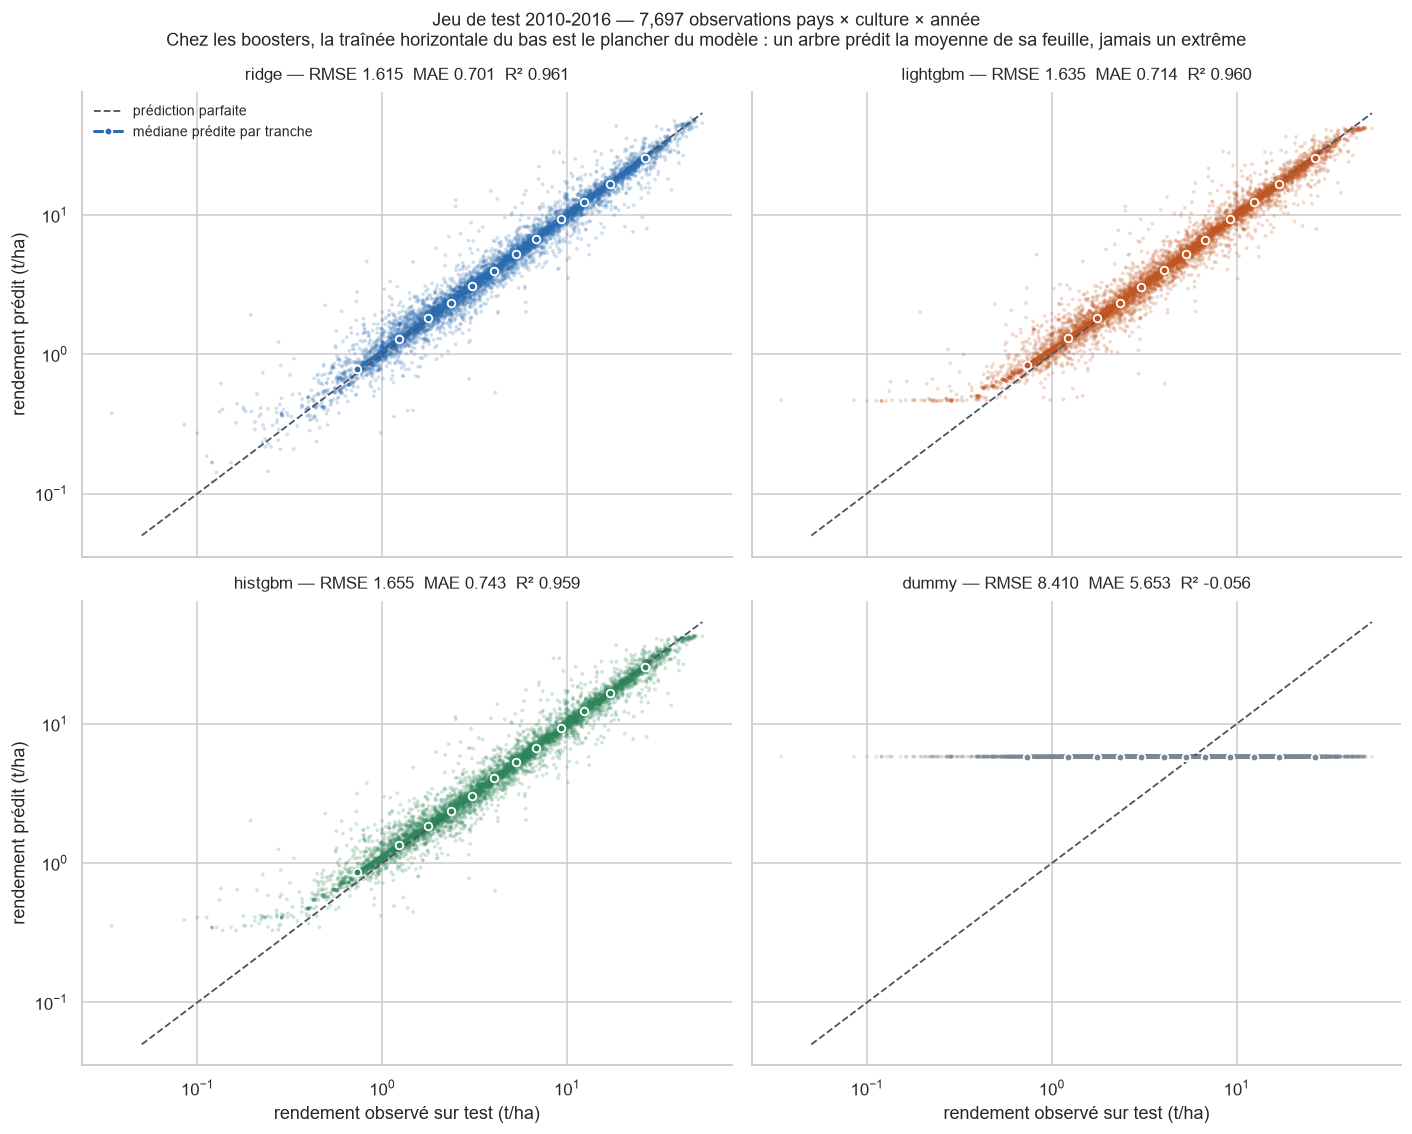

In [26]:
# Les quatre modeles sur `test`. Cette cellule DECRIT, elle ne choisit pas : la
# decision de la section 11 reste celle prise sur `val`.
predictions_test = {nom: m.predict(X_test) for nom, m in modeles.items()}

bilan_test = pd.DataFrame([
    {'modele': nom, **metriques_prediction(y_test, p)}
    for nom, p in predictions_test.items()]).set_index('modele').sort_values('rmse')

# Le gris #c6ccd4 de `dummy` ne contraste qu a 1,62:1 sur blanc : illisible comme
# marque. On reprend le gris de reference du notebook, conforme a 3,66:1.
TONS = {**COULEURS, 'dummy': '#7b8794'}

observe = np.asarray(y_test, dtype=float)
bornes = [max(observe.min(), 0.05), observe.max()]
# Tranches par quantiles : les rendements couvrent deux ordres de grandeur, un pas
# constant mettrait 90 % des observations dans la premiere tranche.
coupures = np.unique(np.quantile(observe, np.linspace(0, 1, 13)))

fig, axes = plt.subplots(2, 2, figsize=(13, 10.5), sharex=True, sharey=True)

for ax, nom in zip(axes.ravel(), bilan_test.index):
    pred = predictions_test[nom]
    ax.scatter(observe, pred, s=6, alpha=0.22, color=TONS[nom], edgecolors='none')
    ax.plot(bornes, bornes, color='#4b5563', lw=1.2, ls='--', zorder=3,
            label='prédiction parfaite')

    # Mediane predite par tranche : elle rend le plafond des arbres visible, la
    # ou le nuage seul reste ambigu.
    rang = np.digitize(observe, coupures[1:-1])
    centres, medianes = [], []
    for k in range(len(coupures) - 1):
        masque = rang == k
        if masque.sum() >= 20:
            centres.append(np.median(observe[masque]))
            medianes.append(np.median(pred[masque]))
    ax.plot(centres, medianes, color=TONS[nom], lw=2, marker='o', ms=5,
            markeredgecolor='white', markeredgewidth=1.2, zorder=4,
            label='médiane prédite par tranche')

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f"{nom} — RMSE {bilan_test.loc[nom, 'rmse']:.3f}  "
                 f"MAE {bilan_test.loc[nom, 'mae']:.3f}  "
                 f"R² {bilan_test.loc[nom, 'r2']:.3f}", fontsize=11, pad=8)
    for cote in ('top', 'right'):
        ax.spines[cote].set_visible(False)

axes[0, 0].legend(frameon=False, fontsize=9, loc='upper left')
for ax in axes[1, :]:
    ax.set_xlabel('rendement observé sur test (t/ha)')
for ax in axes[:, 0]:
    ax.set_ylabel('rendement prédit (t/ha)')

fig.suptitle(
    f"Jeu de test {annees['test'][0]}-{annees['test'][1]} — "
    f'{len(test):,} observations pays × culture × année\n'
    'Chez les boosters, la traînée horizontale du bas est le plancher du modèle : '
    'un arbre prédit la moyenne de sa feuille, jamais un extrême',
    fontsize=12)
fig.tight_layout()
chemin = FIGURES / 'panel_test_quatre_modeles.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.name)
plt.show()

In [27]:
# L'etendue de sortie de chaque modele, comparee a celle de la cible. C'est la
# mesure du plancher visible sur la figure, et du plafond qui ne l'est pas.
etendue = pd.DataFrame(
    [{'modele': nom, 'min prédit': p.min(), 'max prédit': p.max()}
     for nom, p in predictions_test.items() if nom in APPRENANTS]
).set_index('modele')
etendue.loc['— observé —'] = [observe.min(), observe.max()]
print('Étendue des prédictions sur test, en t/ha :\n')
print(etendue.round(3).to_string())
print(f"\nmaximum vu à l'apprentissage : {train[CIBLE].max():.1f} t/ha — "
      'aucun plafond global ne mord donc ici.')

Étendue des prédictions sur test, en t/ha :

             min prédit  max prédit
modele                             
ridge             0.121      50.027
histgbm           0.329      42.881
lightgbm          0.463      42.511
— observé —       0.034      54.000

maximum vu à l'apprentissage : 100.0 t/ha — aucun plafond global ne mord donc ici.


In [28]:
# L'avance de Ridge est-elle uniforme ? RMSE par tranche de rendement observe, et
# part de l'erreur quadratique totale que chaque tranche porte.
rang = np.digitize(observe, coupures[1:-1])
total = float(np.sum((observe - predictions_test[MODELE_RETENU]) ** 2))

bandes = []
for k in range(len(coupures) - 1):
    masque = rang == k
    if masque.sum() < 20:
        continue
    ligne = {'tranche (t/ha)': f'{coupures[k]:5.1f} - {coupures[k + 1]:5.1f}',
             'n': int(masque.sum())}
    for nom in APPRENANTS:
        ligne[nom] = round(float(np.sqrt(np.mean(
            (observe[masque] - predictions_test[nom][masque]) ** 2))), 3)
    ligne['part erreur² (%)'] = round(100 * float(np.sum(
        (observe[masque] - predictions_test[MODELE_RETENU][masque]) ** 2)) / total, 1)
    ligne['meilleur'] = min(APPRENANTS, key=lambda m: ligne[m])
    bandes.append(ligne)

tranches = pd.DataFrame(bandes).set_index('tranche (t/ha)')
print('RMSE par tranche de rendement observé :\n')
print(tranches.to_string())
print(f"\n{MODELE_RETENU} est le meilleur sur "
      f"{(tranches['meilleur'] == MODELE_RETENU).sum()} tranches sur {len(tranches)}.")

RMSE par tranche de rendement observé :

                  n  ridge  histgbm  lightgbm  part erreur² (%)  meilleur
tranche (t/ha)                                                           
 0.0 -   1.0    631  0.311    0.325     0.336               0.3     ridge
 1.0 -   1.5    652  0.356    0.363     0.349               0.4  lightgbm
 1.5 -   2.0    640  0.342    0.351     0.328               0.4  lightgbm
 2.0 -   2.7    643  0.726    0.699     0.702               1.7   histgbm
 2.7 -   3.5    641  0.622    0.638     0.638               1.2     ridge
 3.5 -   4.7    641  0.828    0.811     0.777               2.2  lightgbm
 4.7 -   6.0    642  0.899    0.940     0.905               2.6     ridge
 6.0 -   7.9    641  1.295    1.361     1.367               5.3     ridge
 7.9 -  10.7    641  1.873    1.956     1.883              11.2     ridge
10.7 -  14.8    642  1.898    1.938     1.907              11.5     ridge
14.8 -  21.2    641  2.405    2.320     2.334              18.5   histg

In [29]:
# La ou l'extrapolation se joue vraiment : les lignes dont le rendement depasse
# le maximum historique de LEUR propre serie pays x culture.
historique = np.asarray(
    test.set_index(['Area', 'Item']).index.map(
        train.groupby(['Area', 'Item'])[CIBLE].max()), dtype=float)
connu_serie = ~np.isnan(historique)
hors_domaine = connu_serie & (observe > np.nan_to_num(historique, nan=np.inf))
dans_domaine = connu_serie & ~hors_domaine

print(f'{hors_domaine.sum():,} lignes hors du domaine historique de leur série, '
      f'{dans_domaine.sum():,} dedans\n')
for nom in APPRENANTS:
    dans = np.sqrt(np.mean((observe[dans_domaine]
                            - predictions_test[nom][dans_domaine]) ** 2))
    hors = np.sqrt(np.mean((observe[hors_domaine]
                            - predictions_test[nom][hors_domaine]) ** 2))
    print(f'  {nom:<10} RMSE dans le domaine {dans:.4f}   hors domaine {hors:.4f}')

3,057 lignes hors du domaine historique de leur série, 4,437 dedans

  ridge      RMSE dans le domaine 1.4169   hors domaine 1.8569
  histgbm    RMSE dans le domaine 1.4207   hors domaine 1.9361
  lightgbm   RMSE dans le domaine 1.4069   hors domaine 1.9050


### Ce que la mesure corrige

L'avance de Ridge **n'est pas uniforme** : sur douze tranches de rendement il n'en gagne que sept, et LightGBM le devance dans le domaine historique de chaque série — 1,407 contre 1,417.

Elle se joue sur la **dernière tranche**, de 21 à 54 t/ha : 8 % des lignes, **45 % de l'erreur quadratique totale**, et là Ridge repasse devant (3,740 contre 3,861 et 3,902). Sur les 3 057 lignes dépassant le maximum historique de leur série, il est à 1,857 contre 1,905 et 1,936. **Dans le domaine connu il est battu ; hors du domaine il gagne** — et ce sont ces lignes que produit un découpage chronologique.

D'où la formulation exacte : ce n'est pas qu'un arbre « ne pourrait pas dépasser ce qu'il a appris », le maximum vu à l'apprentissage étant bien au-dessus de tout `test`. C'est que **sa prédiction est une moyenne de feuille**, qui n'atteint jamais les extrêmes. Les boosters s'arrêtent à 42,9 t/ha quand l'observé monte à 54,0 et que Ridge atteint 50,0 : compression intrinsèque à la famille, pas réglable.


In [30]:
# Les runs d'optimisation ne portent que des metriques de `val`. L'evaluation
# finale part donc dans un run SEPARE, marque `phase=test` : melangees dans un
# meme tri par RMSE, les deux phases ne voudraient plus rien dire.
#
# La fonction est idempotente — elle met a jour le run au lieu d'en creer un
# second. Elle reste derriere le verrou : une consultation n'a pas a ecrire
# dans mlflow.db, meme sans rien y dupliquer.
if PUBLIER:
    run_test = training.journaliser_evaluation_test(
        MODELE_RETENU, modele_final, FEATURES, val, test, SOURCE)
    print('Run d évaluation finale journalisé :', run_test)
else:
    print('PUBLIER = False — aucun run journalisé dans mlflow.db.')
    print('Les métriques ci-dessus sont calculées en mémoire et restent exactes.')

PUBLIER = False — aucun run journalisé dans mlflow.db.
Les métriques ci-dessus sont calculées en mémoire et restent exactes.


## 13. Lecture métier

Les coefficients d'un Ridge se lisent directement, à une condition : ils portent sur des variables **standardisées**. Divisés par l'écart-type de leur colonne, ils reviennent à l'unité d'origine.

**Le modèle tient en une phrase** : le rendement de cette année est une moyenne pondérée des trois précédentes — 0,60 pour l'an dernier, 0,20 pour l'avant-dernier, 0,17 pour celui d'avant. Les poids somment à **0,97**, soit un très léger retour vers la moyenne. Tout le reste — pays, culture, température, pesticides — pèse moins d'un dixième de tonne.


In [31]:
if MODELE_RETENU == 'ridge':
    noms = modele_final[:-1].get_feature_names_out()
    coefs = pd.Series(modele_final.named_steps['modele'].coef_, index=noms)

    # Retour a l'unite d'origine pour le bloc quantitatif
    bloc = (modele_final.named_steps['pretraitement']
            .named_transformers_['quantitatives'])
    echelles = pd.Series(bloc.named_steps['standardscaler'].scale_,
                         index=QUANTITATIVES)
    naturels = coefs[QUANTITATIVES] / echelles

    print('Variables quantitatives, en unité d origine :\n')
    print(pd.DataFrame({'coefficient standardisé': coefs[QUANTITATIVES].round(4),
                        'effet par unité (t/ha)': naturels.round(4)}).to_string())

    print('\nEffet propre de chaque culture, à historique égal (t/ha) :')
    effets_item = coefs[[n for n in noms if n.startswith('Item_')]]
    effets_item.index = [n.removeprefix('Item_') for n in effets_item.index]
    print(effets_item.sort_values(ascending=False).round(3).to_string())

    effets_area = coefs[[n for n in noms if n.startswith('Area_')]]
    print(f'\nEffets pays : {len(effets_area)} coefficients, de '
          f'{effets_area.min():.2f} à {effets_area.max():.2f} t/ha')
else:
    print(f'{MODELE_RETENU} n a pas de coefficients lisibles.')
    print('Se reporter à la section 7 : importance par permutation.')

Variables quantitatives, en unité d origine :

              coefficient standardisé  effet par unité (t/ha)
lag1                           3.7569                  0.6019
lag2                           1.2308                  0.1992
lag3                           1.0549                  0.1727
avg_temp                      -0.0550                 -0.0111
rain_mm                       -0.0115                 -0.0000
pesticides_t                   0.0126                  0.0000

Effet propre de chaque culture, à historique égal (t/ha) :
Potatoes                0.388
Cassava                 0.091
Plantains and others    0.080
Sweet potatoes          0.076
Yams                    0.059
Maize                  -0.099
Rice, paddy            -0.101
Wheat                  -0.158
Sorghum                -0.160
Soybeans               -0.175

Effets pays : 206 coefficients, de -0.17 à 0.23 t/ha


In [32]:
# L'erreur du modele traduite en euros. ATTENTION a la lecture : un prix unique
# applique a dix cultures dont les prix reels vont de 213 a 508 EUR/t n'est pas
# une evaluation economique, c'est un changement d'unite. Il donne l'ordre de
# grandeur de ce qu'une erreur de prevision pese, pas une marge.
mae_modele = float(np.abs(y_test - prediction_test).mean())
rmse_modele = float(final.loc['test', 'rmse'])

print(f'Erreur sur test, convertie à {PRIX_TONNE_EUR} EUR/t :\n')
print(f'  MAE   {mae_modele:.4f} t/ha  ->  '
      f'{mae_modele * PRIX_TONNE_EUR:>7.1f} EUR/ha   (l année ordinaire)')
print(f'  RMSE  {rmse_modele:.4f} t/ha  ->  '
      f'{rmse_modele * PRIX_TONNE_EUR:>7.1f} EUR/ha   (poids des grands écarts)')
print(f'\nLe rapport RMSE/MAE vaut {rmse_modele / mae_modele:.1f} : l erreur est')
print('concentree sur une minorite d annees atypiques. Annoncer la seule MAE')
print('sous-estimerait le risque ; annoncer le seul RMSE l exagererait.')

Erreur sur test, convertie à 200 EUR/t :

  MAE   0.7010 t/ha  ->    140.2 EUR/ha   (l année ordinaire)
  RMSE  1.6155 t/ha  ->    323.1 EUR/ha   (poids des grands écarts)

Le rapport RMSE/MAE vaut 2.3 : l erreur est
concentree sur une minorite d annees atypiques. Annoncer la seule MAE
sous-estimerait le risque ; annoncer le seul RMSE l exagererait.


## 14. Export du modèle retenu

Deux écritures distinctes, toutes deux derrière le verrou : le `.joblib` demandé par la mission, et l'alias `champion` du registre, qui enregistre la **décision**.

Le registre du panel est séparé de celui des parcelles simulées — `agritech-rendement-panel` contre `agritech-rendement` : leurs versions n'attendent pas les mêmes colonnes.


In [33]:
# Le verrou gouverne l'ECRITURE. La relecture, elle, a toujours lieu : elle
# verifie que l'artefact present sur le disque rend les memes predictions que
# le modele retenu ci-dessus.
destination = jeu.modele_final

if PUBLIER:
    training.exporter_joblib(modele_final, destination)
    print('Exporté :', destination.name)
elif not destination.exists():
    print(destination.name, 'est absent, et PUBLIER vaut False.')
    print('Pour le produire : passer PUBLIER à True, puis relancer cette cellule.')
else:
    print('PUBLIER = False — artefact existant conservé, vérifié ci-dessous.')

if destination.exists():
    recharge = joblib.load(destination)
    identique = np.allclose(recharge.predict(X_test.head(100)),
                            prediction_test[:100])
    print(f'Relecture et prédiction identiques : {identique}')
    print(f"\nversions attachées : data {versions['data_version']} | "
          f"split {versions['split_version']}")

modele_final_panel.joblib est absent, et PUBLIER vaut False.
Pour le produire : passer PUBLIER à True, puis relancer cette cellule.


In [34]:
# Le .joblib ci-dessus est le livrable demande par la mission. Le registre
# MLflow, lui, enregistre la DECISION : `train.py` y publie une version par
# modele entraine, aucune n'etant privilegiee.
if PUBLIER:
    version_champion = training.promouvoir_champion(MODELE_RETENU, SOURCE)
    print(f'Alias `{ALIAS_CHAMPION}` de {jeu.modele_enregistre} '
          f'-> version {version_champion}')
else:
    # Lecture seule : quelle version porte l'alias aujourd'hui ?
    from mlflow import MlflowClient
    from mlflow.exceptions import MlflowException

    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    try:
        actuel = MlflowClient().get_model_version_by_alias(
            jeu.modele_enregistre, ALIAS_CHAMPION)
        etiquettes = actuel.tags or {}
        print(f'Alias `{ALIAS_CHAMPION}` actuel : {jeu.modele_enregistre} '
              f"version {actuel.version} ({etiquettes.get('modele', 'non tagué')}, "
              f"{etiquettes.get('jeu_de_variables', 'jeu inconnu')})")
        print('Modèle retenu en section 11  :', MODELE_RETENU)
        print()
        print('PUBLIER = False — l alias n a PAS été déplacé.')
    except MlflowException as absence:
        print('Aucun alias `champion` lisible :', absence)

Aucun alias `champion` lisible : Registered model alias champion not found.


## À retenir

- **Ridge est retenu** : RMSE 1,3796 sur `val`, 1,6155 sur `test`, R² 0,961. Sept critères sur sept, dont l'artefact — 8,3 Ko contre 10,2 Mo.
- **Ce qu'il fait : une moyenne pondérée des trois dernières années** (0,60 / 0,20 / 0,17, somme 0,97). Il suit la pente du passé récent, il ne devine pas une rupture. À porter au rapport tel quel : un R² de 0,968 lu seul laisserait croire l'inverse.
- **Trois variables sur huit portent tout le signal.** Retirer les retards coûte 3,8 fois l'erreur ; retirer les cinq autres **améliore** le modèle d'un millième.
- **Les arbres perdent pour une raison structurelle**, mais pas celle qu'on attend : **dans** le domaine historique LightGBM devance Ridge (1,407 contre 1,417), Ridge ne gagne que **hors** de ce domaine (1,857 contre 1,905), sur les 40 % de lignes dépassant le maximum de leur propre série. Une prédiction d'arbre est une moyenne de feuille : elle plafonne à 42,9 t/ha quand l'observé monte à 54,0. Changer de booster n'y changerait rien.
- **La recommandation devient possible** — 15,35 t/ha d'écart entre cultures contre 0,0065 — **mais elle dépend du pays, pas des conditions** : 83,8 % des pays ont une culture de tête invariable. Classement national, jamais conseil personnalisé. Et il manque **six prix sur dix** pour qu'il soit économique.
- **L'erreur n'est pas homogène** : 7,7 % à 16,8 % selon la culture, 1,6 % à 54,0 % selon le pays, écart-type du résidu de 0,24 à 2,95 t/ha du premier au dernier décile — **facteur 12**. Un intervalle de prédiction unique serait ici faux.
- **Portée nationale, pas parcellaire.** `avg_temp` est une moyenne annuelle de pays et `pesticides_t` un tonnage national tous usages : les donner pour des conditions de parcelle serait un contresens. Le panel s'arrête en 2016 : les retards disponibles sont ceux de 2014-2016, donc le modèle prédit 2017, pas l'année en cours.
